# Solución secuencial CPU — ASL

David Domínguez · 23712 / Jonathan Diaz · 23873 / Luis Padilla · 23663

**Ejecución nueva directa en este notebook:** `EXP-008` / `RUN-20261118T041129Z-cpu-notebook-01`.
Cada salida corresponde al código de la celda ejecutada. No se simula `fit` ni se
sustituye por leer un historial. La corrida es adicional a las cinco mediciones
del informe: sus promedios permanecen intactos. Al final se incluyen los registros
históricos completos identificados como tales.

Kernel: **PCUDA**. Preparación de archivos/imágenes en CPU.
Entrenamiento, validación e inferencia en CPU; librerías con paralelismo interno.
Datos congelados:17,400 imágenes,RGB64×64,float32/255;train12180,val2610,test2610.
Se ejecutan15épocas completas por red,batch128,último20,sin EarlyStopping.

Las celdas operativas se extrajeron del AST del controlador medido y se separaron
por fase. Esta ejecución verifica su recorrido en notebook. Para repetir se debe
preparar otro EXP/RUN; este destino no se sobrescribe después de cerrarlo.


In [1]:
from pathlib import Path
import ast, csv, hashlib, json, os, random, subprocess, sys, time
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "docs/Proyecto 3 CUDA.pdf").is_file())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]
EXPERIMENT = ROOT / "resultados/secuencial/EXP-008"
CONFIG = ROOT / "configuraciones/EXP-008.json"
NOTEBOOK = ROOT / "LAB3-DATASCIENCE/Lab3_ASL_Deep_Learning.ipynb"
directory = EXPERIMENT / "RUN-20261118T041129Z-cpu-notebook-01"
repetition = 1
experiment = "EXP-008"
SEED, IMG_SIZE, NUM_CLASSES = 42, 64, 29
__file__ = str(ROOT / "scripts/benchmark_cpu.py")
assert not (directory / "salida.json").exists(), "Corrida cerrada: preparar otro EXP/RUN"
from IPython.display import display, Image as NotebookImage, Markdown
from PIL import Image
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
print("Ejecución real:", experiment, directory.name)
print("Intérprete:", sys.executable)


AssertionError: Corrida cerrada: preparar otro EXP/RUN

In [ ]:
from __future__ import annotations
import argparse
import ast
import csv
from datetime import datetime, timezone
import hashlib
import json
import os
from pathlib import Path
import random
import subprocess
import sys
import time
import traceback

## 1. Configuración, registro y funciones de medición

Las funciones siguientes registran tiempos y estado real; no entrenan al definirse.

In [ ]:
FIELDS = 'experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo'.split(',')

def utc():
    return datetime.now(timezone.utc).isoformat()

def sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

def write_csv(path, rows, fields=None):
    with Path(path).open('w', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=fields or list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def original_namespace():
    """Compile only named definitions, preserving their original source bodies."""
    import numpy as np
    import pandas as pd
    from PIL import Image
    namespace = dict(np=np, pd=pd, Image=Image, random=random, SEED=42, IMG_SIZE=64)
    notebook = json.loads(NOTEBOOK.read_text(encoding='utf-8'))
    names = {'build_sampled_file_list', 'load_images', 'build_cnn_a', 'build_cnn_b', 'build_fc'}
    for index, cell in enumerate(notebook['cells']):
        if cell['cell_type'] != 'code':
            continue
        tree = ast.parse(''.join(cell['source']))
        for node in tree.body:
            if isinstance(node, ast.FunctionDef) and node.name in names:
                exec(compile(ast.Module(body=[node], type_ignores=[]), f'original/celda-{index}', 'exec'), namespace)
    namespace['_notebook'] = notebook
    return namespace

class Recorder:

    def __init__(self, directory, config, repetition):
        self.directory, self.config, self.repetition = (directory, config, repetition)
        self.rows = []
        self.epochs = []

    def state(self, phase, **more):
        write_json(self.directory / 'estado.json', dict(utc=utc(), fase=phase, **more))
        print(f'[{utc()}] {phase} {more}', flush=True)

    def measure(self, phase, function, **load):
        self.state(phase)
        start_utc, start = (utc(), time.perf_counter_ns())
        value = function()
        end, end_utc = (time.perf_counter_ns(), utc())
        self.add(phase, (end - start) / 1000000000.0, start_utc, end_utc, **load)
        return value

    def add(self, phase, seconds, start, end, **load):
        row = dict.fromkeys(FIELDS, '')
        row.update(experimento_id=self.config['experimento_id'], run_id=self.directory.name, dispositivo='cpu', repeticion=self.repetition, fase=phase, tipo_medicion='pared', duracion_s=seconds, inicio_utc=start, fin_utc=end, incluido_resumen='true', estado='completada', configuracion_sha256=sha(CONFIG), datos_sha256=self.config['datos']['manifest_splits_sha256'], evidencia=(self.directory / 'tiempos.csv').relative_to(ROOT).as_posix())
        row.update(load)
        self.rows.append(row)
        write_csv(self.directory / 'tiempos.csv', self.rows, FIELDS)
        print(f'RESULTADO {phase}: {seconds:.6f} s', flush=True)

In [ ]:
config = json.loads(CONFIG.read_text(encoding="utf8"))
print(json.dumps(config, indent=2, ensure_ascii=False))
from registro_notebook import iniciar_monitor
monitor_stop, monitor_thread = iniciar_monitor(directory)


{
  "es_plantilla": false,
  "experimento_id": "EXP-008",
  "creado_utc": "2026-11-18T04:11:29.390536+00:00",
  "pregunta": "Tiempo CPU de las operaciones de procesamiento del laboratorio original completo, con carga fija.",
  "responsable": "Codex por solicitud del usuario; revision docente de codigo y salidas nativas",
  "requisitos": [
    "REQ-03",
    "REQ-07",
    "REQ-12"
  ],
  "decisiones": [
    "DEC-011",
    "DEC-012",
    "DEC-013"
  ],
  "codigo": {
    "commit": "8b8bdec34aadbb91d9b412da12cd8388193427fd",
    "notebook_sha256": "ce8824e860ae7e02684bf702fd6865b7d87cc9eb71917f56bfb0ee8d9ccb8e8a",
    "benchmark_sha256": "c40127fa1e03dfc156b792c997578014b589f6b0650b2a3fe0fb03462c918893",
    "notebook_entrega_plantilla": {
      "ruta": "resultados/preparacion/notebooks-entrega-v03/ASL_Secuencial.plantilla.ipynb",
      "sha256": "e86a4ed6da97674a4f65888c0418ffae9f357302b61a334704bb05ad6c4d9181"
    },
    "presentacion_por_fases": "AST del worker; threadpool_limits manteni

## 2. Datos y funciones originales utilizadas

Código original conservado: carga de imágenes y arquitectura. Las tablas muestran todos los conteos de clases y particiones.

In [ ]:
def build_sampled_file_list(train_dir, classes, samples_per_class, seed=SEED):
    rng = random.Random(seed)
    records = []
    for c in classes:
        files = list((train_dir / c).glob('*.jpg'))
        chosen = rng.sample(files, min(samples_per_class, len(files)))
        for f in chosen:
            records.append({'filepath': str(f), 'label': c})
    return pd.DataFrame(records)

def load_images(df, img_size=IMG_SIZE):
    X = np.zeros((len(df), img_size, img_size, 3), dtype=np.float32)
    y = np.zeros(len(df), dtype=np.int64)
    for i, row in enumerate(df.itertuples()):
        img = Image.open(row.filepath).convert('RGB').resize((img_size, img_size))
        X[i] = np.asarray(img, dtype=np.float32) / 255.0
        y[i] = label_to_idx[row.label]
    return (X, y)

def build_cnn_a():
    model = keras.Sequential([layers.Input((IMG_SIZE, IMG_SIZE, 3)), layers.Conv2D(32, 3, activation='relu'), layers.MaxPooling2D(), layers.Conv2D(64, 3, activation='relu'), layers.MaxPooling2D(), layers.Flatten(), layers.Dense(128, activation='relu'), layers.Dropout(0.3), layers.Dense(NUM_CLASSES, activation='softmax')], name='CNN_A_baseline')
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_cnn_b():

    def bn():
        return layers.BatchNormalization(momentum=0.9)
    model = keras.Sequential([layers.Input((IMG_SIZE, IMG_SIZE, 3)), layers.Conv2D(32, 3, padding='same', activation='relu'), bn(), layers.Conv2D(32, 3, padding='same', activation='relu'), layers.MaxPooling2D(), layers.Dropout(0.25), layers.Conv2D(64, 3, padding='same', activation='relu'), bn(), layers.Conv2D(64, 3, padding='same', activation='relu'), layers.MaxPooling2D(), layers.Dropout(0.25), layers.Conv2D(128, 3, padding='same', activation='relu'), bn(), layers.MaxPooling2D(), layers.Dropout(0.3), layers.Flatten(), layers.Dense(256, activation='relu'), bn(), layers.Dropout(0.4), layers.Dense(NUM_CLASSES, activation='softmax')], name='CNN_B_regularizada')
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_fc(hidden_layers, dropout=0.3, name='FC'):
    model = keras.Sequential([layers.Input((IMG_SIZE, IMG_SIZE, 3)), layers.Flatten(), layers.BatchNormalization()], name=name)
    for units in hidden_layers:
        model.add(layers.Dense(units, activation='relu'))
        model.add(layers.Dropout(dropout))
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [ ]:
datos_manifest = pd.read_csv(ROOT / "resultados/secuencial/EXP-002/manifest_splits.csv", keep_default_na=False)
display(pd.crosstab(datos_manifest.clase, datos_manifest.split, margins=True))
display(datos_manifest.head(12))
print("17,400 rutas/identidades completas en el manifiesto congelado; no se vuelve a muestrear.")


split,test,train,val,All
clase,,,,
A,90,420,90,600
B,90,420,90,600
C,90,420,90,600
D,90,420,90,600
E,90,420,90,600
F,90,420,90,600
G,90,420,90,600
H,90,420,90,600
I,90,420,90,600


,dataset_id,ruta_relativa,sha256,clase,label_idx,split,orden
0,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/G/G655.jpg,c0bd22cd6c98e4c44f55768591883b3f09de1ea56a4d5086e1588f9c6bba1408,G,6,train,0
1,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/U/U872.jpg,99f8225febb986777b61f51b64a28dbe383ed4207961f574b12fc05ab16dcfd9,U,20,train,1
2,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/del/del1194.jpg,f1c0ce06721a2800426c606c91cf5ef7e1a8eda6b64e6a1d7fce5fd5241674fd,del,26,train,2
3,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/X/X1315.jpg,8aa9f39fb29eb8d6a3b3d08b8b2798ec2a87ae9d0acdefd00b7b4ab04c1b777f,X,23,train,3
4,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/L/L1488.jpg,de633263269d5853ae4e0fb29cde3d8b7117757b87c7c00dfc80e0b3ad211824,L,11,train,4
5,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/Q/Q2458.jpg,f91ac91df6363041db78bed1b5f6965394ccd957d6ee7a26889f4fe1551726c3,Q,16,train,5
6,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/R/R1802.jpg,a0ed4e004c4ecd3aae62a9bfca0f17322cf9a0fd1582dd5fc10d378a469df3a2,R,17,train,6
7,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/F/F639.jpg,db1e01d002a4453522ed1da46a5c7d52dd17ab290943f908bd6e520d4f94c7ce,F,5,train,7
8,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/V/V2125.jpg,51bb2043c46f2e3cab613a68a5b582ff7191610a6b405ba5dd8f16b0f889cb65,V,21,train,8
9,DAT-03-EXP-002,asl_alphabet_train/asl_alphabet_train/P/P1458.jpg,b16b54cab32dbec8c12826f245e32f66a02fd5d1bed59affb41ba895232642f7,P,15,train,9


17,400 rutas/identidades completas en el manifiesto congelado; no se vuelve a muestrear.


## Configuración efectiva del dispositivo y verificación de entradas

In [ ]:
config = json.loads(CONFIG.read_text(encoding='utf-8'))

if sha(NOTEBOOK) != config['codigo']['notebook_sha256'] or sha(__file__) != config['codigo']['benchmark_sha256']:
    raise ValueError('Source identity differs from frozen experiment.')

threads = config['cpu']['hilos_matematicos']

for key, value in {'CUDA_VISIBLE_DEVICES': '-1', 'OMP_NUM_THREADS': str(threads), 'MKL_NUM_THREADS': str(threads), 'OPENBLAS_NUM_THREADS': str(threads), 'TF_NUM_INTRAOP_THREADS': str(threads), 'TF_NUM_INTEROP_THREADS': '1', 'TF_DETERMINISTIC_OPS': '1', 'TF_ENABLE_ONEDNN_OPTS': '1'}.items():
    os.environ[key] = value

import numpy as np

import pandas as pd

import tensorflow as tf

from sklearn.decomposition import PCA

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, confusion_matrix

from threadpoolctl import threadpool_limits, threadpool_info

tf.config.set_visible_devices([], 'GPU')

tf.config.threading.set_intra_op_parallelism_threads(threads)

tf.config.threading.set_inter_op_parallelism_threads(1)

tf.config.experimental.enable_op_determinism()

tf.keras.mixed_precision.set_global_policy('float32')

if tf.config.get_visible_devices('GPU'):
    raise ValueError('GPU visible in CPU benchmark.')

namespace = original_namespace()

namespace.update(keras=tf.keras, layers=tf.keras.layers, NUM_CLASSES=29)

classes = list(json.loads((EXPERIMENT / 'label_mapping.json').read_text(encoding='utf-8')).values())

namespace['label_to_idx'] = {name: i for i, name in enumerate(classes)}

data_root = Path(config['datos']['ruta'])

if sha(EXPERIMENT / 'manifest_splits.csv') != config['datos']['manifest_splits_sha256']:
    raise ValueError('Split manifest changed.')

manifest = pd.read_csv(EXPERIMENT / 'manifest_splits.csv', keep_default_na=False)

frames = {}

for split in ('train', 'val', 'test'):
    frame = manifest[manifest.split == split].sort_values('orden').copy()
    frame['filepath'] = frame.ruta_relativa.map(lambda s: str(data_root / s))
    frame['label'] = frame.clase
    frames[split] = frame

for item in manifest.itertuples():
    if sha(data_root / item.ruta_relativa) != item.sha256:
        raise ValueError(f'Input changed: {item.ruta_relativa}')

record = Recorder(directory, config, repetition)

(directory / 'configuracion.json').write_bytes(CONFIG.read_bytes())

write_json(directory / 'hardware.json', dict(cpu=config['cpu'], tensorflow=tf.__version__, visibles=[str(d) for d in tf.config.get_visible_devices()], logical=[str(d) for d in tf.config.list_logical_devices()], test_device=tf.constant([1.0]).device, build=tf.sysconfig.get_build_info(), threadpools=threadpool_info(), variables={k: os.environ.get(k) for k in ('CUDA_VISIBLE_DEVICES', 'OMP_NUM_THREADS', 'MKL_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'TF_NUM_INTRAOP_THREADS', 'TF_NUM_INTEROP_THREADS', 'TF_DETERMINISTIC_OPS', 'TF_ENABLE_ONEDNN_OPTS')}))

models, warmup, initial = ({}, {}, {})

warm_x, warm_y = namespace['load_images'](frames['train'].head(148))

warm_vx, warm_vy = namespace['load_images'](frames['val'].head(128))

data_directory = ROOT / 'data' / EXPERIMENT.name / directory.name

data_directory.mkdir(parents=True, exist_ok=False)

def augmented(name):
    namespace['best_cnn_name'] = name
    tree = ast.parse(''.join(namespace['_notebook']['cells'][52]['source']))
    nodes = [node for node in tree.body if isinstance(node, ast.Assign) and all((not isinstance(t, ast.Name) or t.id != 'history_aug' for t in node.targets)) or (isinstance(node, ast.Expr) and isinstance(node.value, ast.Call) and isinstance(node.value.func, ast.Attribute) and (node.value.func.attr == 'compile'))]
    exec(compile(ast.Module(body=nodes, type_ignores=[]), 'original/celda-52-configuracion', 'exec'), namespace)
    return namespace['cnn_aug']

In [ ]:
print((directory / "hardware.json").read_text(encoding="utf8"))

{
  "cpu": {
    "modelo": "AMD Ryzen 5 4600H with Radeon Graphics",
    "nucleos_fisicos": 6,
    "nucleos_logicos": 12,
    "ram_bytes": 16558346240,
    "hilos_matematicos": 6,
    "intra_op": 6,
    "inter_op": 1,
    "workers_preparacion": 1,
    "afinidad": "sin restriccion adicional",
    "gpu_visible": false
  },
  "tensorflow": "2.22.0-rc0",
  "visibles": [
    "PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')"
  ],
  "logical": [
    "LogicalDevice(name='/device:CPU:0', device_type='CPU')"
  ],
  "test_device": "/job:localhost/replica:0/task:0/device:CPU:0",
  "build": {
    "is_cuda_build": false,
    "is_rocm_build": false,
    "is_tensorrt_build": false,
    "msvcp_dll_names": "msvcp140.dll,msvcp140_1.dll"
  },
  "threadpools": [
    {
      "user_api": "blas",
      "internal_api": "openblas",
      "num_threads": 12,
      "prefix": "libscipy_openblas",
      "filepath": "C:\\Users\\David\\Documents\\2026\\S2\\PARALELA\\CUDA\\PROYECTO-CUDA\\proyectoCUDA-p

In [ ]:
threadpool_guard = threadpool_limits(limits=6)
threadpool_guard.__enter__()
print("Límite de bibliotecas matemáticas: 6 hilos")


Límite de bibliotecas matemáticas: 6 hilos


## Calentamiento y restauración de estados

In [ ]:
for name, seed in config['aleatoriedad']['semillas_modelos'].items():
    record.state('inicializacion_y_warmup', modelo=name)
    tf.keras.utils.set_random_seed(seed)
    start = time.perf_counter()
    if name == 'CNN-A':
        model = namespace['build_cnn_a']()
    elif name == 'CNN-B':
        model = namespace['build_cnn_b']()
    elif name == 'FC-A':
        model = namespace['build_fc']([128, 64], dropout=0.3, name='FC_A_pequena')
    elif name == 'FC-B':
        model = namespace['build_fc']([512, 256, 128], dropout=0.4, name='FC_B_grande')
    else:
        model = augmented(name.split('+')[0])
    model.jit_compile = False
    model.optimizer.build(model.trainable_variables)
    variables = list(model.variables) + list(model.optimizer.variables)
    saved = [v.numpy().copy() for v in variables]
    h = hashlib.sha256()
    for array in saved:
        h.update(str((array.shape, str(array.dtype))).encode())
        h.update(array.tobytes())
    fingerprint = h.hexdigest()
    state_path = data_directory / f'{name}.estado-inicial.npz'
    np.savez(state_path, *saved)
    model.fit(warm_x, warm_y, validation_data=(warm_vx, warm_vy), epochs=1, batch_size=128, shuffle=False, verbose=0)
    if len(variables) != len(list(model.variables) + list(model.optimizer.variables)):
        raise ValueError('Warmup created unexpected state; cannot restore exactly.')
    for variable, value in zip(variables, saved):
        variable.assign(value)
    if any((not np.array_equal(v.numpy(), a) for v, a in zip(variables, saved))):
        raise ValueError('Warmup state restoration failed.')
    initial[name] = dict(state_sha256=fingerprint, archivo=state_path.relative_to(ROOT).as_posix(), archivo_sha256=sha(state_path), variables=len(variables), arquitectura=model.to_json(), compile=model.get_compile_config())
    warmup[name] = time.perf_counter() - start
    models[name] = model
    del saved

write_json(directory / 'estados-iniciales.json', initial)

write_json(directory / 'warmup.json', warmup)

[2026-11-18T04:11:58.438877+00:00] inicializacion_y_warmup {'modelo': 'CNN-A'}


[2026-11-18T04:12:00.902499+00:00] inicializacion_y_warmup {'modelo': 'CNN-B'}


[2026-11-18T04:12:05.864769+00:00] inicializacion_y_warmup {'modelo': 'FC-A'}


[2026-11-18T04:12:07.803452+00:00] inicializacion_y_warmup {'modelo': 'FC-B'}


[2026-11-18T04:12:10.163352+00:00] inicializacion_y_warmup {'modelo': 'CNN-A+aug'}


[2026-11-18T04:12:12.644027+00:00] inicializacion_y_warmup {'modelo': 'CNN-B+aug'}


## Preparación de datos en CPU

In [ ]:
metrics, training_history, epoch_rows = ({}, {}, [])

inputs = {}

wall_start_utc, wall_start = (utc(), time.perf_counter_ns())

def load_all():
    for split in ('train', 'val', 'test'):
        inputs[split] = namespace['load_images'](frames[split])

record.measure('preparacion_cpu', load_all, muestras=17400)

x, y = inputs['train']

vx, vy = inputs['val']

tx, ty = inputs['test']

[2026-11-18T04:12:18.376023+00:00] preparacion_cpu {}


RESULTADO preparacion_cpu: 16.785118 s


train X (12180, 64, 64, 3) float32 y (12180,) int64 rango 0.0 1.0
val X (2610, 64, 64, 3) float32 y (2610,) int64 rango 0.0 1.0
test X (2610, 64, 64, 3) float32 y (2610,) int64 rango 0.0 1.0


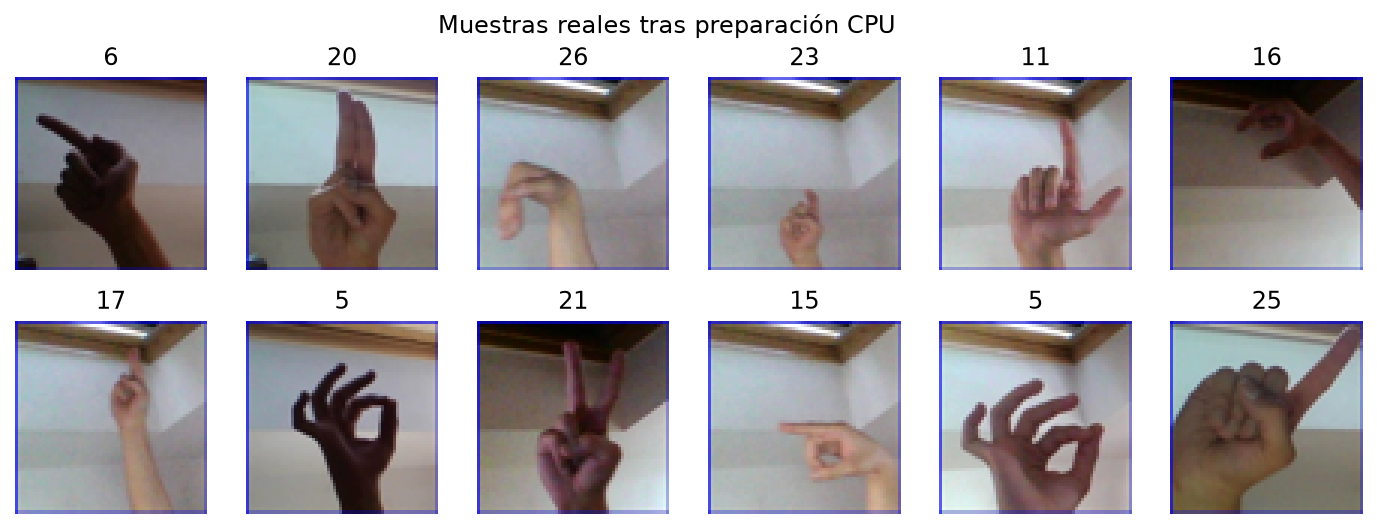

In [ ]:
for etiqueta, (imagenes, clases_y) in inputs.items():
    print(etiqueta, "X", imagenes.shape, imagenes.dtype, "y", clases_y.shape, clases_y.dtype,
          "rango", float(imagenes.min()), float(imagenes.max()))
fig, axes = plt.subplots(2,6,figsize=(12,4))
for i,ax in enumerate(axes.flat):
    ax.imshow(x[i]); ax.set_title(str(y[i])); ax.axis("off")
fig.suptitle("Muestras reales tras preparación CPU")
from registro_notebook import mostrar_figura
mostrar_figura(fig)


## Callbacks y entrenamiento/evaluación originales

In [ ]:
class Epochs(tf.keras.callbacks.Callback):

    def __init__(self, name):
        super().__init__()
        self.name = name
        self.validation = 0.0
        self.epoch_validation = 0.0

    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
        self.epoch_validation = 0.0
        record.state('entrenamiento', modelo=self.name, epoca=epoch + 1)

    def on_test_begin(self, logs=None):
        self.test_start = time.perf_counter()

    def on_test_end(self, logs=None):
        seconds = time.perf_counter() - self.test_start
        self.validation += seconds
        self.epoch_validation += seconds

    def on_epoch_end(self, epoch, logs=None):
        epoch_rows.append(dict(modelo=self.name, epoca=epoch + 1, duracion_s=time.perf_counter() - self.start, validacion_s=self.epoch_validation, **logs))
        print(f'EPOCH {self.name} {epoch + 1}/15 {logs}', flush=True)

def fit_evaluate(name):
    tf.keras.utils.set_random_seed(config['aleatoriedad']['semillas_modelos'][name])
    callback = Epochs(name)
    history = record.measure(f'entrenamiento_{name}', lambda: models[name].fit(x, y, validation_data=(vx, vy), epochs=15, batch_size=128, shuffle=True, callbacks=[callback], verbose=0), epocas=15, pasos=1440, muestras=12180 * 15, batch_size=128, motivo='Incluye validacion; callbacks y duraciones anidadas conservados.')
    training_history[name] = history.history
    record.add(f'validacion_anidada_{name}', callback.validation, '', '', epocas=15, muestras=2610 * 15, motivo='Subintervalo de fit: no sumar al total ni tratar como fase adicional.')
    metrics[name] = record.measure(f'evaluacion_{name}', lambda: models[name].evaluate(tx, ty, verbose=0, return_dict=True), muestras=2610)
    write_csv(directory / 'epocas.csv', epoch_rows)
    write_json(directory / 'metricas-parciales.json', metrics)

## Entrenamiento y evaluación CNN-A

In [ ]:
fit_evaluate('CNN-A')

[2026-11-18T04:12:35.763415+00:00] entrenamiento_CNN-A {}


[2026-11-18T04:12:35.949855+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 1}


EPOCH CNN-A 1/15 {'accuracy': 0.17233169078826904, 'loss': 2.941843032836914, 'val_accuracy': 0.40306514501571655, 'val_loss': 2.09909987449646}


[2026-11-18T04:12:45.095392+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 2}


EPOCH CNN-A 2/15 {'accuracy': 0.4241379201412201, 'loss': 1.8811553716659546, 'val_accuracy': 0.6061302423477173, 'val_loss': 1.3572086095809937}


[2026-11-18T04:12:53.454690+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 3}


... (25 outputs left out)

RESULTADO entrenamiento_CNN-A: 130.499553 s


RESULTADO validacion_anidada_CNN-A: 8.221943 s


[2026-11-18T04:14:46.270999+00:00] evaluacion_CNN-A {}


RESULTADO evaluacion_CNN-A: 0.771945 s


,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.172332,2.941843,0.403065,2.099100
2,0.424138,1.881155,0.606130,1.357209
3,0.575123,1.341297,0.688506,1.035756
4,0.668145,1.044865,0.791571,0.745192
5,0.740722,0.800756,0.814943,0.637783
6,0.795320,0.642778,0.843295,0.529143
7,0.820525,0.548367,0.864751,0.444818
8,0.846305,0.463251,0.886207,0.385231
9,0.867898,0.411775,0.907280,0.312747


Prueba: {'accuracy': 0.9306513667106628, 'loss': 0.21349219977855682}
Arquitectura real:


Model: "CNN_A_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,886,681 (18.64 MB)

 Trainable params: 1,628,893 (6.21 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,257,788 (12.43 MB)

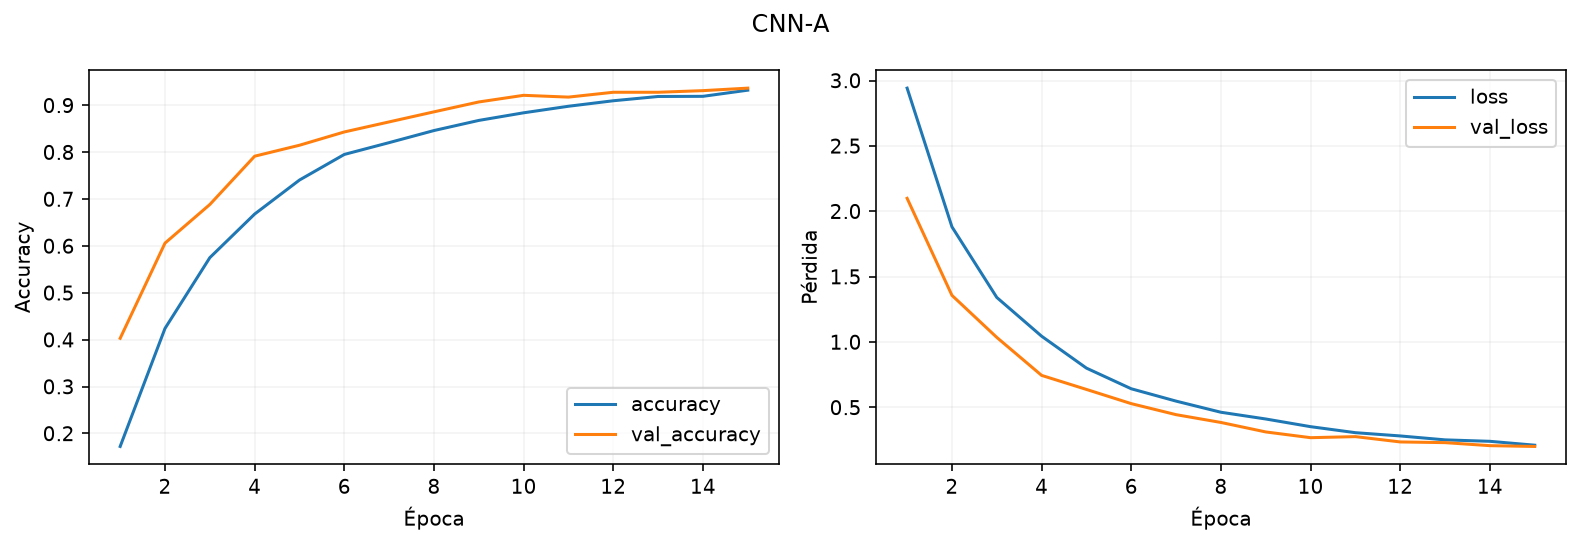

In [ ]:
modelo_tabla = 'CNN-A'
display(pd.DataFrame(training_history[modelo_tabla], index=range(1,16)).rename_axis("epoca"))
print("Prueba:", metrics[modelo_tabla])
print("Arquitectura real:")
models[modelo_tabla].summary()
hist = pd.DataFrame(training_history[modelo_tabla])
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
for name in ("accuracy","val_accuracy"): ax[0].plot(range(1,len(hist)+1),hist[name],label=name)
for name in ("loss","val_loss"): ax[1].plot(range(1,len(hist)+1),hist[name],label=name)
for a in ax: a.set_xlabel("Época"); a.legend(); a.grid(alpha=.15)
ax[0].set_ylabel("Accuracy"); ax[1].set_ylabel("Pérdida")
fig.suptitle(modelo_tabla); fig.tight_layout()
from registro_notebook import mostrar_figura
mostrar_figura(fig)


## Entrenamiento y evaluación CNN-B

In [ ]:
fit_evaluate('CNN-B')

[2026-11-18T04:14:47.383916+00:00] entrenamiento_CNN-B {}


[2026-11-18T04:14:47.529373+00:00] entrenamiento {'modelo': 'CNN-B', 'epoca': 1}


EPOCH CNN-B 1/15 {'accuracy': 0.2495894879102707, 'loss': 2.776747226715088, 'val_accuracy': 0.22452107071876526, 'val_loss': 7.6706132888793945}


[2026-11-18T04:15:43.628997+00:00] entrenamiento {'modelo': 'CNN-B', 'epoca': 2}


EPOCH CNN-B 2/15 {'accuracy': 0.5485221743583679, 'loss': 1.4916183948516846, 'val_accuracy': 0.5896551609039307, 'val_loss': 1.9189932346343994}


[2026-11-18T04:16:38.287981+00:00] entrenamiento {'modelo': 'CNN-B', 'epoca': 3}


... (25 outputs left out)

RESULTADO entrenamiento_CNN-B: 818.108888 s


RESULTADO validacion_anidada_CNN-B: 31.152741 s


[2026-11-18T04:28:25.499842+00:00] evaluacion_CNN-B {}


RESULTADO evaluacion_CNN-B: 2.266801 s


,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.249589,2.776747,0.224521,7.670613
2,0.548522,1.491618,0.589655,1.918993
3,0.743678,0.849019,0.675479,1.207509
4,0.844910,0.524003,0.815326,0.788757
5,0.895567,0.356808,0.828736,0.597973
6,0.935468,0.224724,0.786590,0.827753
7,0.947455,0.179724,0.917625,0.318944
8,0.964286,0.127405,0.939847,0.198315
9,0.974631,0.097240,0.975096,0.083106


Prueba: {'accuracy': 0.9823755025863647, 'loss': 0.06345177441835403}
Arquitectura real:


Model: "CNN_B_regularizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 29)             │         7,453 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,736,697 (25.70 MB)

 Trainable params: 2,245,245 (8.56 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 4,490,492 (17.13 MB)

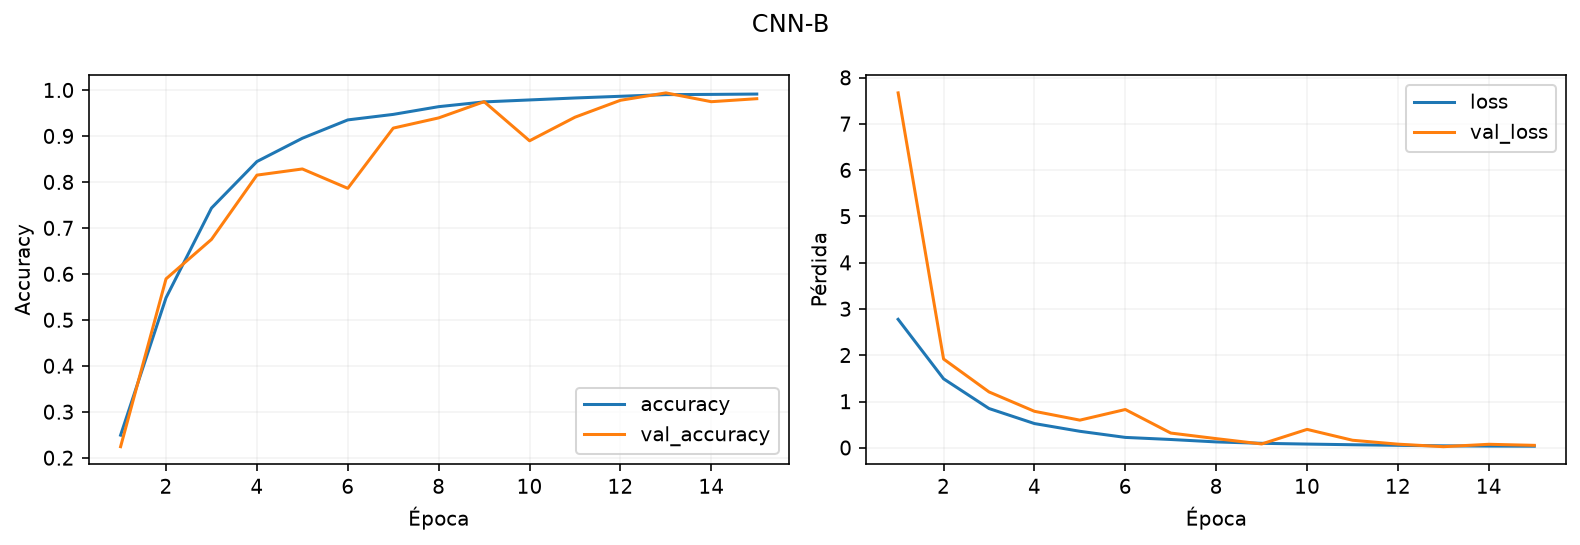

In [ ]:
modelo_tabla = 'CNN-B'
display(pd.DataFrame(training_history[modelo_tabla], index=range(1,16)).rename_axis("epoca"))
print("Prueba:", metrics[modelo_tabla])
print("Arquitectura real:")
models[modelo_tabla].summary()
hist = pd.DataFrame(training_history[modelo_tabla])
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
for name in ("accuracy","val_accuracy"): ax[0].plot(range(1,len(hist)+1),hist[name],label=name)
for name in ("loss","val_loss"): ax[1].plot(range(1,len(hist)+1),hist[name],label=name)
for a in ax: a.set_xlabel("Época"); a.legend(); a.grid(alpha=.15)
ax[0].set_ylabel("Accuracy"); ax[1].set_ylabel("Pérdida")
fig.suptitle(modelo_tabla); fig.tight_layout()
from registro_notebook import mostrar_figura
mostrar_figura(fig)


## Diagnóstico de la CNN seleccionada

In [ ]:
best_cnn = max(('CNN-A', 'CNN-B'), key=lambda name: metrics[name]['accuracy'])

probs = record.measure('diagnostico_cnn', lambda: models[best_cnn].predict(tx, verbose=0), muestras=2610)

confusion = confusion_matrix(ty, np.argmax(probs, axis=1))

[2026-11-18T04:28:28.083547+00:00] diagnostico_cnn {}


RESULTADO diagnostico_cnn: 2.455987 s


## Entrenamiento y evaluación FC-A

In [ ]:
fit_evaluate('FC-A')

[2026-11-18T04:28:30.661611+00:00] entrenamiento_FC-A {}


[2026-11-18T04:28:30.793507+00:00] entrenamiento {'modelo': 'FC-A', 'epoca': 1}


EPOCH FC-A 1/15 {'accuracy': 0.08218390494585037, 'loss': 4.152613639831543, 'val_accuracy': 0.07586207240819931, 'val_loss': 3.2913665771484375}


[2026-11-18T04:28:34.202333+00:00] entrenamiento {'modelo': 'FC-A', 'epoca': 2}


EPOCH FC-A 2/15 {'accuracy': 0.1310344785451889, 'loss': 3.1408960819244385, 'val_accuracy': 0.15402299165725708, 'val_loss': 3.0917515754699707}


[2026-11-18T04:28:36.959940+00:00] entrenamiento {'modelo': 'FC-A', 'epoca': 3}


... (25 outputs left out)

RESULTADO entrenamiento_FC-A: 42.163768 s


RESULTADO validacion_anidada_FC-A: 2.348872 s


[2026-11-18T04:29:12.831469+00:00] evaluacion_FC-A {}


RESULTADO evaluacion_FC-A: 0.381475 s


,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.082184,4.152614,0.075862,3.291367
2,0.131034,3.140896,0.154023,3.091752
3,0.158949,2.955222,0.211494,2.837924
4,0.184729,2.815850,0.254023,2.584154
5,0.207307,2.690429,0.281609,2.402166
6,0.227504,2.569278,0.319157,2.278628
7,0.247783,2.479751,0.334100,2.164684
8,0.259031,2.407609,0.374330,2.045426
9,0.281691,2.311532,0.381609,1.965323


Prueba: {'accuracy': 0.530651330947876, 'loss': 1.5230441093444824}
Arquitectura real:


Model: "FC_A_pequena"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 29)             │         1,885 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,847,705 (18.49 MB)

 Trainable params: 1,607,709 (6.13 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 3,215,420 (12.27 MB)

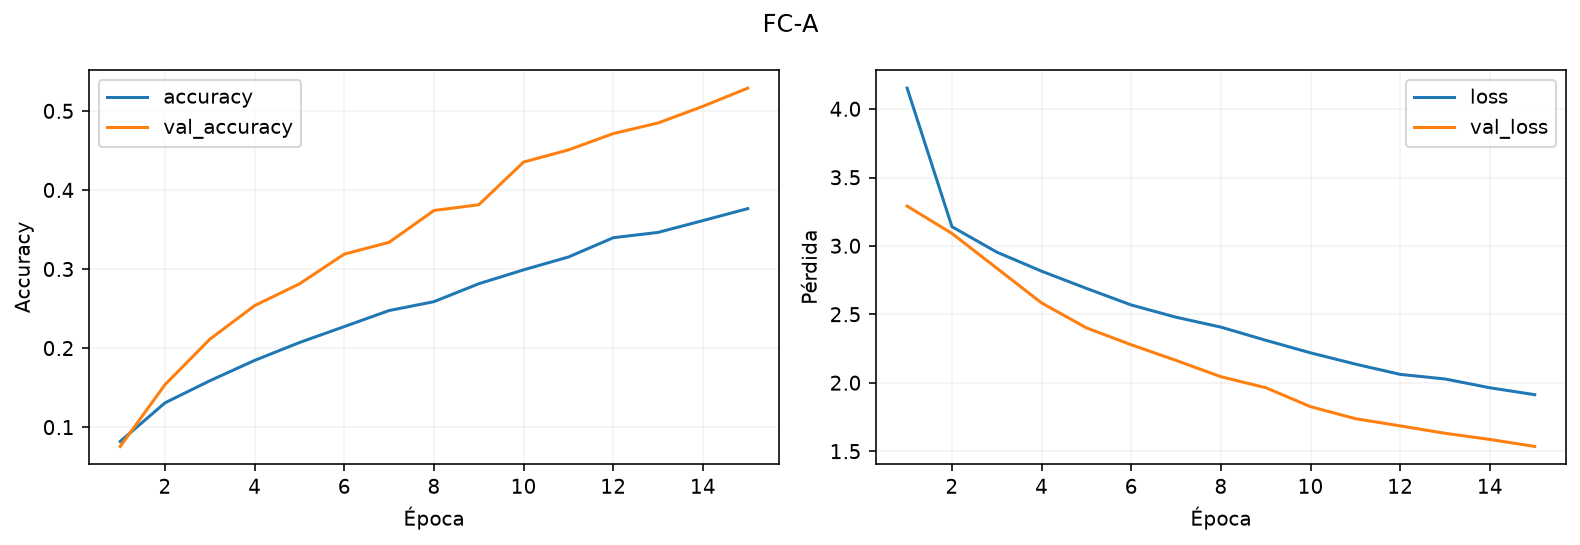

In [ ]:
modelo_tabla = 'FC-A'
display(pd.DataFrame(training_history[modelo_tabla], index=range(1,16)).rename_axis("epoca"))
print("Prueba:", metrics[modelo_tabla])
print("Arquitectura real:")
models[modelo_tabla].summary()
hist = pd.DataFrame(training_history[modelo_tabla])
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
for name in ("accuracy","val_accuracy"): ax[0].plot(range(1,len(hist)+1),hist[name],label=name)
for name in ("loss","val_loss"): ax[1].plot(range(1,len(hist)+1),hist[name],label=name)
for a in ax: a.set_xlabel("Época"); a.legend(); a.grid(alpha=.15)
ax[0].set_ylabel("Accuracy"); ax[1].set_ylabel("Pérdida")
fig.suptitle(modelo_tabla); fig.tight_layout()
from registro_notebook import mostrar_figura
mostrar_figura(fig)


## Entrenamiento y evaluación FC-B

In [ ]:
fit_evaluate('FC-B')

[2026-11-18T04:29:13.509269+00:00] entrenamiento_FC-B {}


[2026-11-18T04:29:13.636575+00:00] entrenamiento {'modelo': 'FC-B', 'epoca': 1}


EPOCH FC-B 1/15 {'accuracy': 0.0517241396009922, 'loss': 5.050939559936523, 'val_accuracy': 0.05363984778523445, 'val_loss': 3.348174810409546}


[2026-11-18T04:29:19.848810+00:00] entrenamiento {'modelo': 'FC-B', 'epoca': 2}


EPOCH FC-B 2/15 {'accuracy': 0.07495895028114319, 'loss': 3.3826398849487305, 'val_accuracy': 0.11762452125549316, 'val_loss': 3.2416882514953613}


[2026-11-18T04:29:25.553538+00:00] entrenamiento {'modelo': 'FC-B', 'epoca': 3}


... (25 outputs left out)

RESULTADO entrenamiento_FC-B: 86.277678 s


RESULTADO validacion_anidada_FC-B: 3.823730 s


[2026-11-18T04:30:39.793308+00:00] evaluacion_FC-B {}


RESULTADO evaluacion_FC-B: 0.516642 s


,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.051724,5.050940,0.053640,3.348175
2,0.074959,3.382640,0.117625,3.241688
3,0.106979,3.173376,0.156322,3.032495
4,0.122660,3.057127,0.196552,2.838329
5,0.140640,2.929129,0.208429,2.696107
6,0.158867,2.827862,0.250192,2.552922
7,0.179310,2.712492,0.284291,2.408978
8,0.203038,2.632856,0.305364,2.278836
9,0.208374,2.544663,0.320690,2.161579


Prueba: {'accuracy': 0.44291186332702637, 'loss': 1.7380640506744385}
Arquitectura real:


Model: "FC_B_grande"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 12288)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 12288)          │        49,152 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 512)            │     6,291,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 29)             │         3,741 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,478,105 (74.30 MB)

 Trainable params: 6,484,509 (24.74 MB)

 Non-trainable params: 24,576 (96.00 KB)

 Optimizer params: 12,969,020 (49.47 MB)

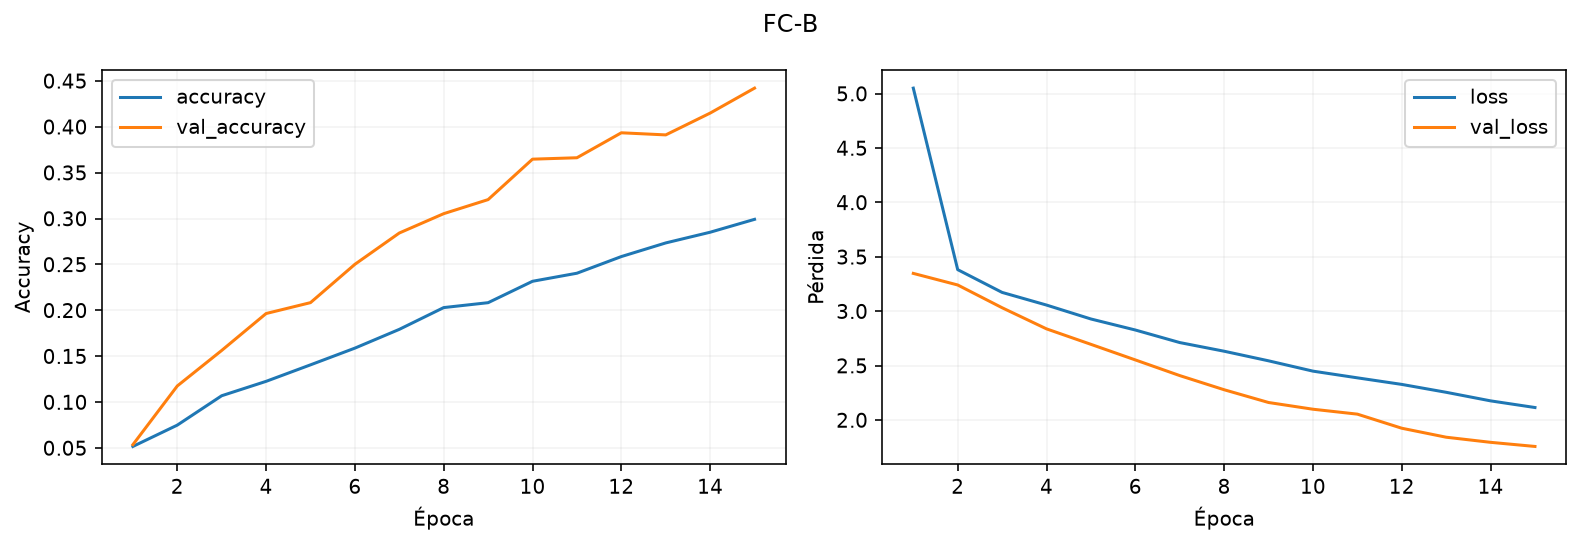

In [ ]:
modelo_tabla = 'FC-B'
display(pd.DataFrame(training_history[modelo_tabla], index=range(1,16)).rename_axis("epoca"))
print("Prueba:", metrics[modelo_tabla])
print("Arquitectura real:")
models[modelo_tabla].summary()
hist = pd.DataFrame(training_history[modelo_tabla])
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
for name in ("accuracy","val_accuracy"): ax[0].plot(range(1,len(hist)+1),hist[name],label=name)
for name in ("loss","val_loss"): ax[1].plot(range(1,len(hist)+1),hist[name],label=name)
for a in ax: a.set_xlabel("Época"); a.legend(); a.grid(alpha=.15)
ax[0].set_ylabel("Accuracy"); ax[1].set_ylabel("Pérdida")
fig.suptitle(modelo_tabla); fig.tight_layout()
from registro_notebook import mostrar_figura
mostrar_figura(fig)


## PCA: ajuste únicamente con train

In [ ]:
pca = PCA(n_components=150, random_state=42)

projections = {}

def project():
    projections['train'] = pca.fit_transform(x.reshape(len(x), -1))
    projections['val'] = pca.transform(vx.reshape(len(vx), -1))
    projections['test'] = pca.transform(tx.reshape(len(tx), -1))

record.measure('pca', project, muestras=17400)

[2026-11-18T04:30:40.678251+00:00] pca {}


RESULTADO pca: 3.936913 s


## Random Forest: ajuste y validación

In [ ]:
forests = {}

forest_val = {}

for name, trees, depth in (('RF-A', 100, None), ('RF-B', 300, 30)):
    forest = RandomForestClassifier(n_estimators=trees, max_depth=depth, random_state=42, n_jobs=-1)
    record.measure(f'entrenamiento_{name}', lambda: forest.fit(projections['train'], y), muestras=12180)
    pred = record.measure(f'validacion_{name}', lambda: forest.predict(projections['val']), muestras=2610)
    forest_val[name] = accuracy_score(vy, pred)
    forests[name] = forest

best_rf = max(forest_val, key=forest_val.get)

rf_pred = record.measure('evaluacion_RF', lambda: forests[best_rf].predict(projections['test']), muestras=2610)

metrics[best_rf] = dict(accuracy=accuracy_score(ty, rf_pred), val_accuracy=forest_val[best_rf])

[2026-11-18T04:30:44.644125+00:00] entrenamiento_RF-A {}


RESULTADO entrenamiento_RF-A: 2.719464 s


[2026-11-18T04:30:47.367068+00:00] validacion_RF-A {}


RESULTADO validacion_RF-A: 0.055168 s


[2026-11-18T04:30:47.427543+00:00] entrenamiento_RF-B {}


RESULTADO entrenamiento_RF-B: 8.127897 s


[2026-11-18T04:30:55.559426+00:00] validacion_RF-B {}


RESULTADO validacion_RF-B: 0.137022 s


[2026-11-18T04:30:55.701604+00:00] evaluacion_RF {}


RESULTADO evaluacion_RF: 0.139924 s


## Entrenamiento y evaluación con aumento

In [ ]:
aug_name = best_cnn + '+aug'

fit_evaluate(aug_name)

[2026-11-18T04:30:55.873101+00:00] entrenamiento_CNN-B+aug {}


[2026-11-18T04:30:56.083630+00:00] entrenamiento {'modelo': 'CNN-B+aug', 'epoca': 1}


EPOCH CNN-B+aug 1/15 {'accuracy': 0.1667487621307373, 'loss': 3.1161551475524902, 'val_accuracy': 0.12413793057203293, 'val_loss': 7.48199987411499}


[2026-11-18T04:31:53.065349+00:00] entrenamiento {'modelo': 'CNN-B+aug', 'epoca': 2}


EPOCH CNN-B+aug 2/15 {'accuracy': 0.3724958896636963, 'loss': 2.11655592918396, 'val_accuracy': 0.3850574791431427, 'val_loss': 3.662924289703369}


[2026-11-18T04:32:48.863446+00:00] entrenamiento {'modelo': 'CNN-B+aug', 'epoca': 3}


... (25 outputs left out)

RESULTADO entrenamiento_CNN-B+aug: 839.796843 s


RESULTADO validacion_anidada_CNN-B+aug: 32.525816 s


[2026-11-18T04:44:55.678787+00:00] evaluacion_CNN-B+aug {}


RESULTADO evaluacion_CNN-B+aug: 2.338843 s


,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,0.166749,3.116155,0.124138,7.482000
2,0.372496,2.116556,0.385057,3.662924
3,0.534647,1.488962,0.489272,2.207257
4,0.661494,1.074360,0.638697,1.740575
5,0.727750,0.857903,0.681992,0.988877
6,0.791626,0.660692,0.625670,1.389341
7,0.823563,0.549118,0.777012,0.679668
8,0.848604,0.470066,0.882759,0.656125
9,0.874548,0.402788,0.898851,0.303756


Prueba: {'accuracy': 0.9704980850219727, 'loss': 0.09022021293640137}
Arquitectura real:


Model: "CNN_B_con_augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ CNN_B_regularizada (Sequential) │ (None, 29)             │     2,246,205 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,736,697 (25.70 MB)

 Trainable params: 2,245,245 (8.56 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 4,490,492 (17.13 MB)

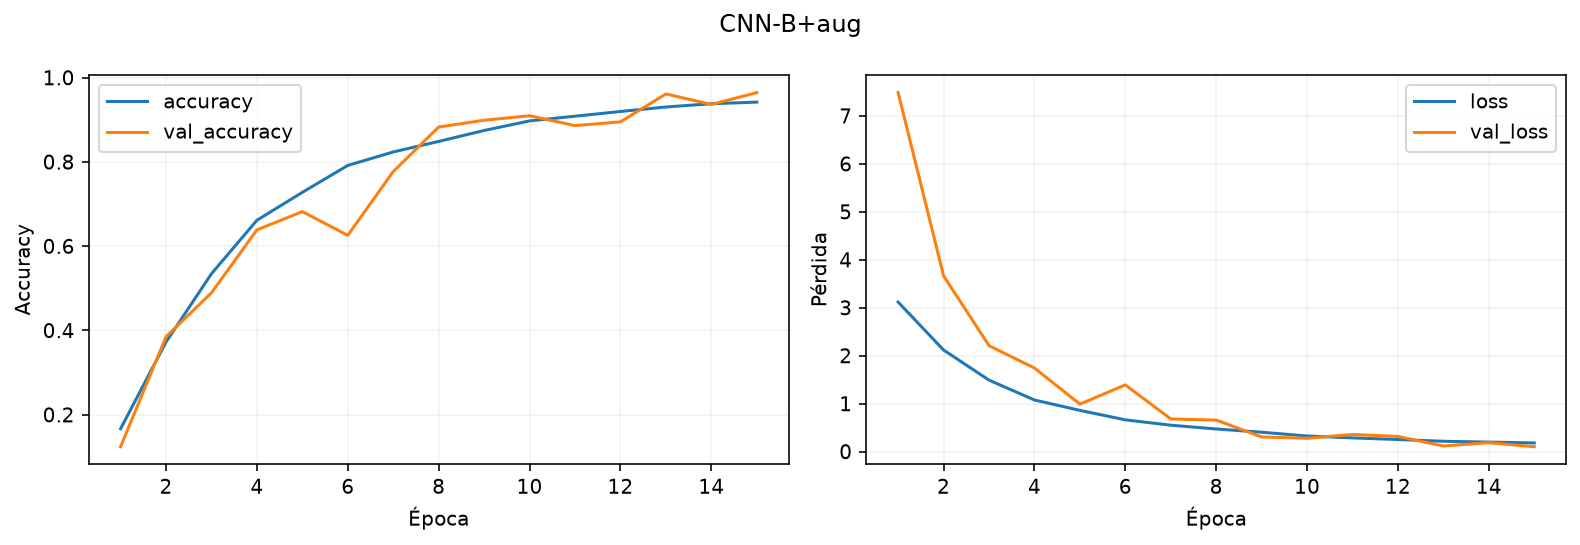

In [ ]:
modelo_tabla = aug_name
display(pd.DataFrame(training_history[modelo_tabla], index=range(1,16)).rename_axis("epoca"))
print("Prueba:", metrics[modelo_tabla])
print("Arquitectura real:")
models[modelo_tabla].summary()
hist = pd.DataFrame(training_history[modelo_tabla])
fig, ax = plt.subplots(1,2,figsize=(11,3.8))
for name in ("accuracy","val_accuracy"): ax[0].plot(range(1,len(hist)+1),hist[name],label=name)
for name in ("loss","val_loss"): ax[1].plot(range(1,len(hist)+1),hist[name],label=name)
for a in ax: a.set_xlabel("Época"); a.legend(); a.grid(alpha=.15)
ax[0].set_ylabel("Accuracy"); ax[1].set_ylabel("Pérdida")
fig.suptitle(modelo_tabla); fig.tight_layout()
from registro_notebook import mostrar_figura
mostrar_figura(fig)


## Selección e inferencia sobre fotografías propias

In [ ]:
registry = {name: models[name] for name in ('CNN-A', 'CNN-B', 'FC-A', 'FC-B', aug_name)}

registry[best_rf] = forests[best_rf]

final = max(metrics, key=lambda name: metrics[name]['accuracy'])

own_files = sorted((ROOT / 'LAB3-DATASCIENCE/imagenes_grupo').glob('*.*'))

from PIL import Image

own_results = []

def prepare_one(path):
    with Image.open(path) as image:
        return np.asarray(image.convert('RGB').resize((64, 64)), dtype=np.float32) / 255.0

def predict_one(name, array):
    if name.startswith('RF'):
        return int(registry[name].predict(pca.transform(array.reshape(1, -1)))[0])
    return int(np.argmax(registry[name].predict(array[np.newaxis, ...], verbose=0)[0]))

def own_inference():
    for path in own_files:
        pred = predict_one(final, prepare_one(path))
        own_results.append(dict(modelo=final, etapa='final', archivo=path.name, real=path.stem.split('_')[0], prediccion=classes[pred]))
    arrays = [prepare_one(path) for path in own_files]
    for name in registry:
        for path, array in zip(own_files, arrays):
            pred = predict_one(name, array)
            own_results.append(dict(modelo=name, etapa='todos', archivo=path.name, real=path.stem.split('_')[0], prediccion=classes[pred]))

record.measure('inferencia_grupo', own_inference, muestras=len(own_files), motivo='15+90 predicciones individuales; 30 preprocesamientos; sin renderizar figuras.')

wall_end, wall_end_utc = (time.perf_counter_ns(), utc())

record.add('pipeline_total', (wall_end - wall_start) / 1000000000.0, wall_start_utc, wall_end_utc, epocas=75, pasos=7200, muestras=17400, batch_size=128)

[2026-11-18T04:44:58.328023+00:00] inferencia_grupo {}


RESULTADO inferencia_grupo: 44.140463 s


RESULTADO pipeline_total: 2004.096636 s


## Identidad de tensores y persistencia de resultados

In [ ]:
fingerprints = {}

for split, (array, labels) in inputs.items():
    if array.shape != (len(frames[split]), 64, 64, 3) or not np.isfinite(array).all():
        raise ValueError('Invalid prepared tensors.')
    fingerprints[split] = dict(shape=list(array.shape), dtype=str(array.dtype), images_sha256=hashlib.sha256(array.tobytes()).hexdigest(), labels_sha256=hashlib.sha256(labels.tobytes()).hexdigest(), min=float(array.min()), max=float(array.max()))

write_json(directory / 'tensores.json', fingerprints)

write_json(directory / 'historiales.json', training_history)

write_csv(directory / 'predicciones_grupo.csv', own_results)

write_csv(directory / 'confusion.csv', [dict(clase=classes[i], **{c: int(v) for c, v in zip(classes, row)}) for i, row in enumerate(confusion)])

write_json(directory / 'metricas.json', dict(modelos=metrics, mejor_cnn=best_cnn, mejor_rf=best_rf, modelo_final=final, pca_varianza=float(pca.explained_variance_ratio_.sum()), grupo_accuracy={name: sum((row['real'].upper() == row['prediccion'].upper() for row in own_results if row['etapa'] == 'todos' and row['modelo'] == name)) / len(own_files) for name in registry}))

model_paths = {}

for name in registry:
    if name.startswith('RF'):
        continue
    path = data_directory / f'{name}.keras'
    registry[name].save(path)
    model_paths[name] = dict(ruta=path.relative_to(ROOT).as_posix(), sha256=sha(path))

import joblib

for name, obj in ((best_rf, forests[best_rf]), ('PCA', pca)):
    path = data_directory / f'{name}.joblib'
    joblib.dump(obj, path)
    model_paths[name] = dict(ruta=path.relative_to(ROOT).as_posix(), sha256=sha(path))

write_json(directory / 'modelos-guardados.json', model_paths)

record.state('completada', pipeline_s=(wall_end - wall_start) / 1000000000.0)

[2026-11-18T04:45:51.955550+00:00] completada {'pipeline_s': 2004.0966361}


## Resultados completos de esta ejecución

In [ ]:
print((directory / "metricas.json").read_text(encoding="utf8"))
display(pd.read_csv(directory / "tiempos.csv"))
display(pd.read_csv(directory / "epocas.csv"))


{
  "modelos": {
    "CNN-A": {
      "accuracy": 0.9306513667106628,
      "loss": 0.21349219977855682
    },
    "CNN-B": {
      "accuracy": 0.9823755025863647,
      "loss": 0.06345177441835403
    },
    "FC-A": {
      "accuracy": 0.530651330947876,
      "loss": 1.5230441093444824
    },
    "FC-B": {
      "accuracy": 0.44291186332702637,
      "loss": 1.7380640506744385
    },
    "RF-B": {
      "accuracy": 0.8977011494252873,
      "val_accuracy": 0.9088122605363985
    },
    "CNN-B+aug": {
      "accuracy": 0.9704980850219727,
      "loss": 0.09022021293640137
    }
  },
  "mejor_cnn": "CNN-B",
  "mejor_rf": "RF-B",
  "modelo_final": "CNN-B",
  "pca_varianza": 0.9621036052703857,
  "grupo_accuracy": {
    "CNN-A": 0.13333333333333333,
    "CNN-B": 0.13333333333333333,
    "FC-A": 0.06666666666666667,
    "FC-B": 0.06666666666666667,
    "CNN-B+aug": 0.13333333333333333,
    "RF-B": 0.0
  }
}



,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,preparacion_cpu,pared,16.785118,2026-11-18T04:12:18.376884+00:00,2026-11-18T04:12:35.162019+00:00,NaN,NaN,17400,NaN,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,NaN
1,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,entrenamiento_CNN-A,pared,130.499553,2026-11-18T04:12:35.764336+00:00,2026-11-18T04:14:46.264051+00:00,15.0,1440.0,182700,128.0,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
2,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,validacion_anidada_CNN-A,pared,8.221943,NaN,NaN,15.0,NaN,39150,NaN,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
3,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,evaluacion_CNN-A,pared,0.771945,2026-11-18T04:14:46.271788+00:00,2026-11-18T04:14:47.043766+00:00,NaN,NaN,2610,NaN,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,NaN
4,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,entrenamiento_CNN-B,pared,818.108888,2026-11-18T04:14:47.384804+00:00,2026-11-18T04:28:25.493720+00:00,15.0,1440.0,182700,128.0,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
5,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,validacion_anidada_CNN-B,pared,31.152741,NaN,NaN,15.0,NaN,39150,NaN,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
6,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,evaluacion_CNN-B,pared,2.266801,2026-11-18T04:28:25.500933+00:00,2026-11-18T04:28:27.767760+00:00,NaN,NaN,2610,NaN,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,NaN
7,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,diagnostico_cnn,pared,2.455987,2026-11-18T04:28:28.084222+00:00,2026-11-18T04:28:30.540243+00:00,NaN,NaN,2610,NaN,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,NaN
8,EXP-008,RUN-20261118T041129Z-cpu-notebook-01,cpu,1,entrenamiento_FC-A,pared,42.163768,2026-11-18T04:28:30.662313+00:00,2026-11-18T04:29:12.826098+00:00,15.0,1440.0,182700,128.0,True,completada,c092ec5fe01a0dd7d9722255596d10cad514051fa41b291a4d434c197111c7bf,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/tiempos.csv,Incluye validacion; callbacks y 

,modelo,epoca,duracion_s,validacion_s,accuracy,loss,val_accuracy,val_loss
0,CNN-A,1,9.143064,0.682568,0.172332,2.941843,0.403065,2.099100
1,CNN-A,2,8.357553,0.540243,0.424138,1.881155,0.606130,1.357209
2,CNN-A,3,8.280078,0.512899,0.575123,1.341297,0.688506,1.035756
3,CNN-A,4,8.296015,0.511296,0.668145,1.044865,0.791571,0.745192
4,CNN-A,5,8.906109,0.515353,0.740722,0.800756,0.814943,0.637783
5,CNN-A,6,8.378913,0.525864,0.795320,0.642778,0.843295,0.529143
6,CNN-A,7,9.262414,0.515215,0.820525,0.548367,0.864751,0.444818
7,CNN-A,8,8.214212,0.524787,0.846305,0.463251,0.886207,0.385231
8,CNN-A,9,8.492466,0.638111,0.867898,0.411775,0.907280,0.312747
9,CNN-A,10,10.618475,0.650167,0.884154,0.353000,0.921456,0.268770


,A,B,C,D,E,F,G,H,I,J,K,L,M,N,O,P,Q,R,S,T,U,V,W,X,Y,Z,del,nothing,space
clase,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A,88,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
B,0,90,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
C,0,0,90,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
D,0,1,0,89,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
E,0,0,0,0,89,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
F,0,0,0,0,0,90,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
G,0,0,0,0,0,0,90,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
H,0,0,0,0,0,0,0,90,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
I,0,0,0,0,1,0,0,0,89,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


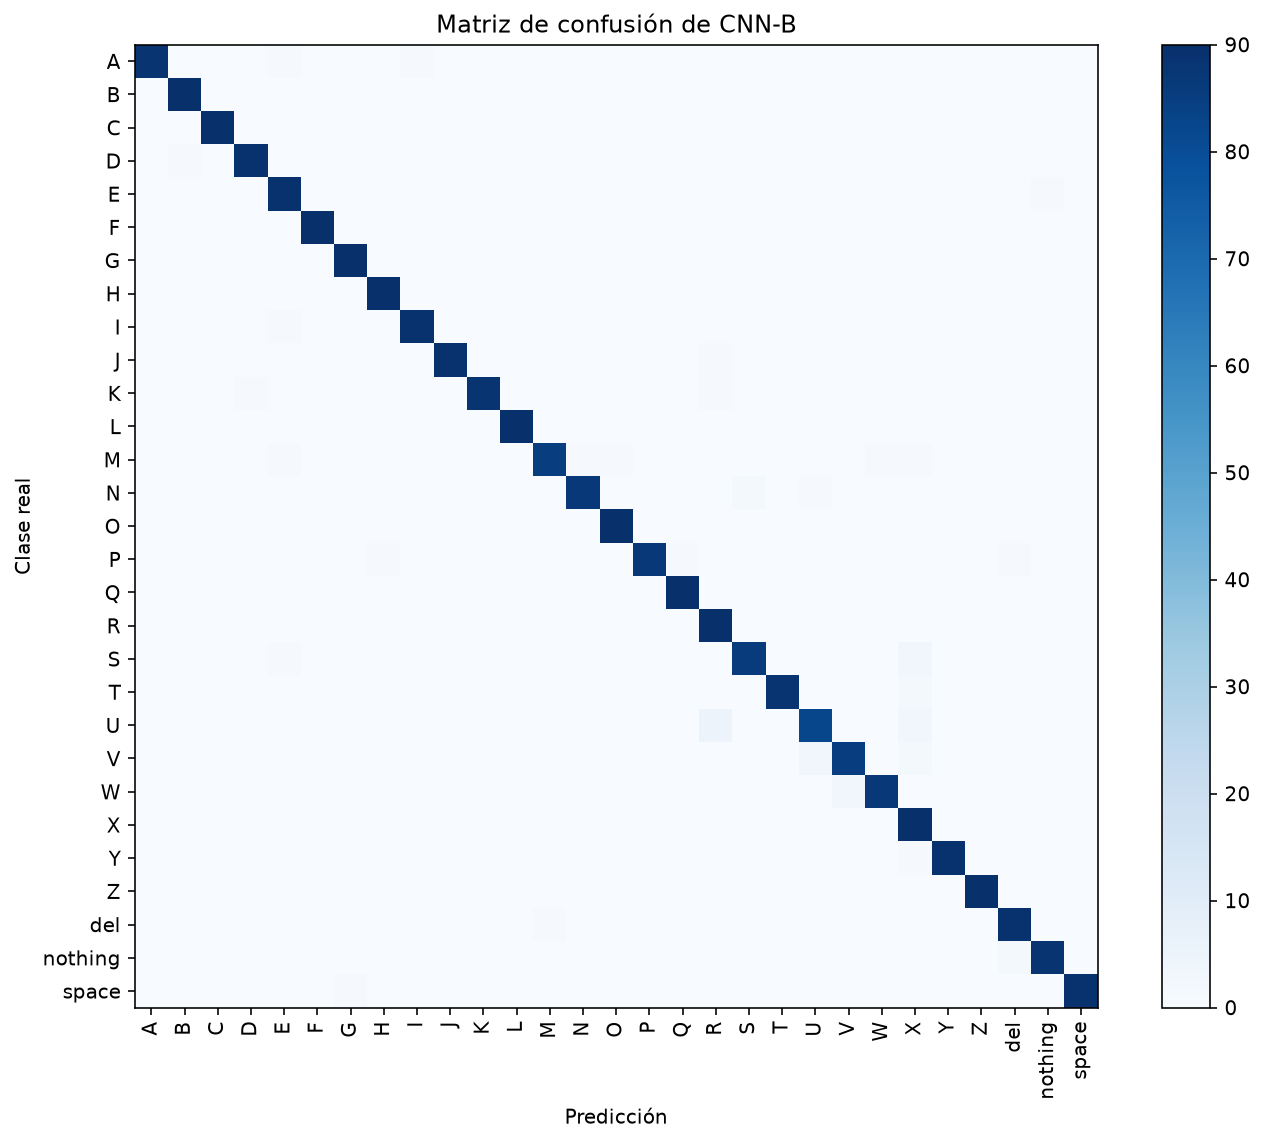

,modelo,etapa,archivo,real,prediccion
0,CNN-B,final,A_luis.jpeg,A,E
1,CNN-B,final,B_luis.jpeg,B,N
2,CNN-B,final,C_luis.jpeg,C,C
3,CNN-B,final,D_luis.jpeg,D,R
4,CNN-B,final,G_luis.jpeg,G,del
5,CNN-B,final,K_bran.jpeg,K,V
6,CNN-B,final,L_bran.jpeg,L,V
7,CNN-B,final,M_bran.jpeg,M,N
8,CNN-B,final,N_bran.jpeg,N,N
9,CNN-B,final,R_bran.jpeg,R,U


Modelo final: CNN-B ; PCA varianza: 0.9621036
{
  "CNN-A": {
    "ruta": "data/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/CNN-A.keras",
    "sha256": "b9f29583c1dae8c02678d5b886d30421a3b416c89b74753ea7900dc52d7137d6"
  },
  "CNN-B": {
    "ruta": "data/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/CNN-B.keras",
    "sha256": "135946f8e7f00f626d31d6bd21c26c6a0defab3c0e36d332968e6f8b9e688ba7"
  },
  "FC-A": {
    "ruta": "data/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/FC-A.keras",
    "sha256": "e77c275ed429630adc9fdca3a27ea67d720bb870bcb9a878917f03a39b3253ae"
  },
  "FC-B": {
    "ruta": "data/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/FC-B.keras",
    "sha256": "cb493ad40be6b080160a7eff891a3440ee05f5520e2bc54817626c2bfa529826"
  },
  "CNN-B+aug": {
    "ruta": "data/EXP-008/RUN-20261118T041129Z-cpu-notebook-01/CNN-B+aug.keras",
    "sha256": "19b9e90a43c0913ecbd558a0fdb91182598863e259330b53888d135a4b02a19e"
  },
  "RF-B": {
    "ruta": "data/EXP-008/RUN-20261118T041129Z-cpu-noteb

In [ ]:
confusion_df = pd.read_csv(directory / "confusion.csv", index_col=0)
display(confusion_df)
fig, ax = plt.subplots(figsize=(10,8)); im=ax.imshow(confusion_df.values,cmap="Blues")
ax.set(xticks=range(29),yticks=range(29),xticklabels=confusion_df.columns,yticklabels=confusion_df.index,
       xlabel="Predicción",ylabel="Clase real",title="Matriz de confusión de "+best_cnn)
ax.tick_params(axis="x",labelrotation=90);fig.colorbar(im,ax=ax);fig.tight_layout();mostrar_figura(fig)
propias = pd.read_csv(directory / "predicciones_grupo.csv")
display(propias)
print("Modelo final:",final,"; PCA varianza:",pca.explained_variance_ratio_.sum())
print((directory / "modelos-guardados.json").read_text(encoding="utf8"))


## Recursos utilizados, logs y cierre de la ejecución nueva

,utc,transcurrido_s,fase,modelo,epoca,cpu_procesos_pct,rss_bytes,gpu_util_pct,gpu_mem_util_pct,gpu_mem_used_mib,gpu_temperatura_c,cpu_logico_00_pct,cpu_logico_01_pct,cpu_logico_02_pct,cpu_logico_03_pct,cpu_logico_04_pct,cpu_logico_05_pct,cpu_logico_06_pct,cpu_logico_07_pct,cpu_logico_08_pct,cpu_logico_09_pct,cpu_logico_10_pct,cpu_logico_11_pct
0,2026-11-18T04:11:37.514059+00:00,0.002081,inicio,NaN,NaN,0.000000,137756672,0.0,0.0,0.0,48.0,60.0,60.0,60.0,40.0,20.0,40.0,40.0,0.0,20.0,60.0,60.0,20.0
1,2026-11-18T04:11:38.521166+00:00,1.014632,inicio,NaN,NaN,77.156607,223428608,0.0,0.0,0.0,48.0,37.9,26.2,30.9,18.5,21.5,15.2,48.5,27.7,66.2,20.0,43.9,26.9
2,2026-11-18T04:11:39.527839+00:00,2.020881,inicio,NaN,NaN,76.087017,255254528,0.0,0.0,0.0,48.0,18.8,32.8,43.8,26.2,10.9,12.5,26.6,10.9,70.8,20.3,29.7,25.0
3,2026-11-18T04:11:40.536773+00:00,3.032186,inicio,NaN,NaN,74.161618,284508160,0.0,0.0,0.0,48.0,33.8,26.2,33.3,24.2,24.6,26.6,26.2,22.7,72.7,12.3,24.6,18.2
4,2026-11-18T04:11:41.550695+00:00,4.044217,inicio,NaN,NaN,88.003701,321970176,0.0,0.0,0.0,49.0,37.7,27.3,27.3,46.2,10.8,13.8,26.2,9.4,84.8,7.7,12.3,16.7
5,2026-11-18T04:11:42.562447+00:00,5.056762,inicio,NaN,NaN,70.984499,349913088,0.0,0.0,0.0,49.0,16.7,39.4,12.5,10.9,9.4,6.2,20.3,7.7,71.9,1.6,28.1,24.6
6,2026-11-18T04:11:43.571761+00:00,6.066873,inicio,NaN,NaN,72.702449,392626176,0.0,0.0,0.0,49.0,16.2,29.2,11.9,13.6,9.1,17.9,7.7,7.6,54.5,7.7,20.0,10.6
7,2026-11-18T04:11:44.583195+00:00,7.078146,inicio,NaN,NaN,75.709017,416108544,0.0,0.0,0.0,48.0,12.1,13.8,3.1,1.5,15.4,3.1,7.7,0.0,66.2,4.6,15.4,6.2
8,2026-11-18T04:11:45.598348+00:00,8.091641,inicio,NaN,NaN,90.959977,442327040,0.0,0.0,0.0,48.0,1.5,7.7,6.1,17.2,3.1,4.6,1.5,0.0,24.6,27.7,10.8,26.2
9,2026-11-18T04:11:46.608754+00:00,9.102923,inicio,NaN,NaN,100.429495,443392000,0.0,0.0,0.0,48.0,17.2,6.2,22.7,15.4,18.8,20.3,21.9,13.8,23.4,23.4,80.0,10.6


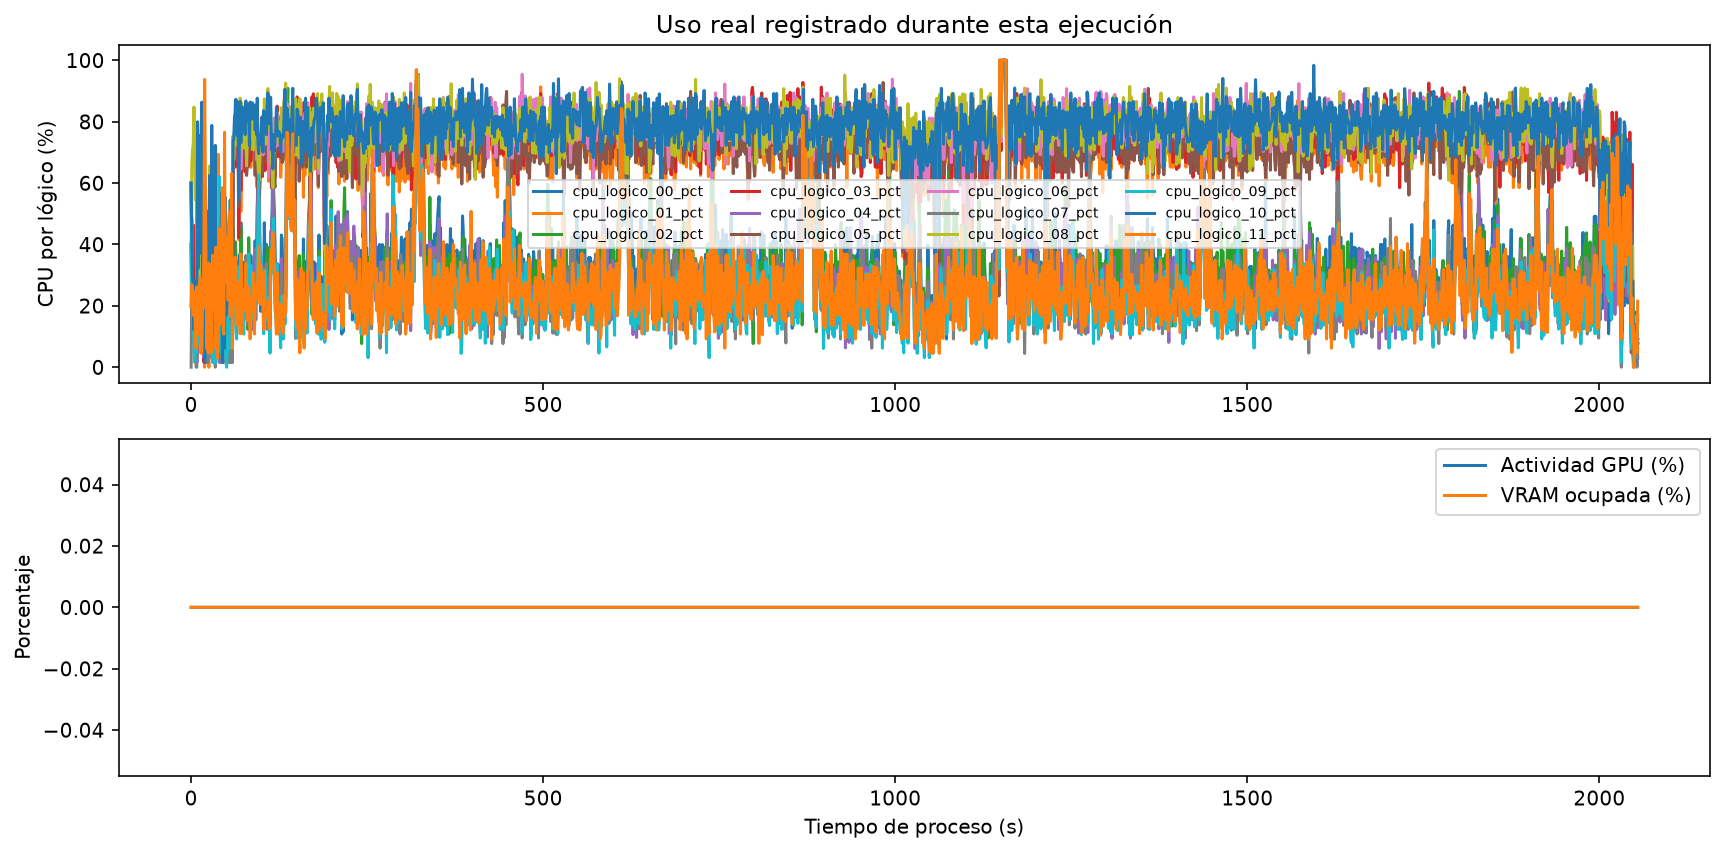

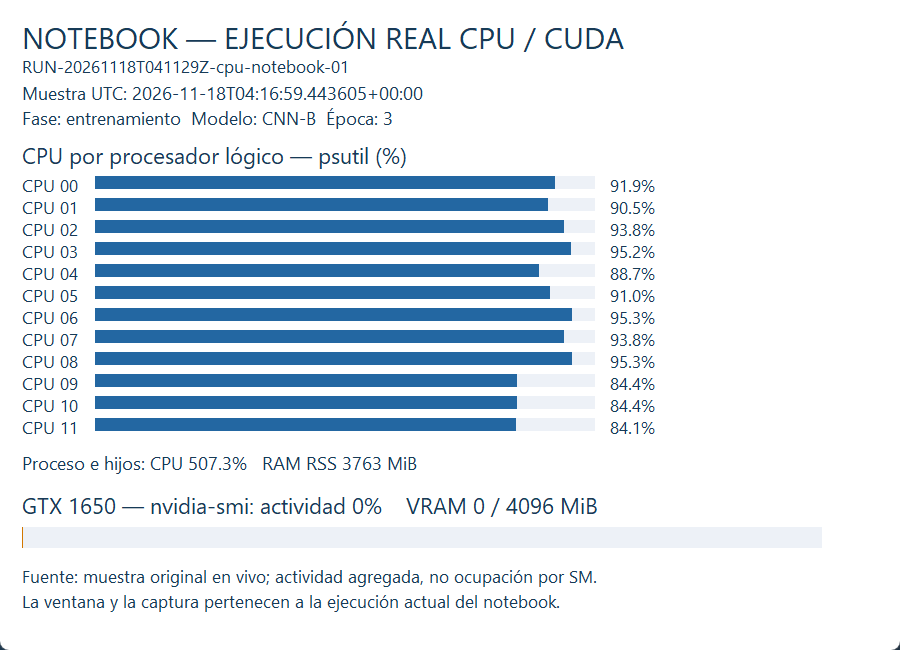

captura-cpu-sostenido.png {
  "tipo": "captura_original_monitor_en_vivo",
  "captura_utc": "2026-11-18T04:17:00.614874+00:00",
  "run_id": "RUN-20261118T041129Z-cpu-notebook-01",
  "muestra_original": {
    "utc": "2026-11-18T04:16:59.443605+00:00",
    "transcurrido_s": "321.91136699996423",
    "fase": "entrenamiento",
    "modelo": "CNN-B",
    "epoca": "3",
    "cpu_procesos_pct": "507.27870165054566",
    "rss_bytes": "3946213376",
    "gpu_util_pct": "0.0",
    "gpu_mem_util_pct": "0.0",
    "gpu_mem_used_mib": "0.0",
    "gpu_temperatura_c": "54.0",
    "cpu_logico_00_pct": "91.9",
    "cpu_logico_01_pct": "90.5",
    "cpu_logico_02_pct": "93.8",
    "cpu_logico_03_pct": "95.2",
    "cpu_logico_04_pct": "88.7",
    "cpu_logico_05_pct": "91.0",
    "cpu_logico_06_pct": "95.3",
    "cpu_logico_07_pct": "93.8",
    "cpu_logico_08_pct": "95.3",
    "cpu_logico_09_pct": "84.4",
    "cpu_logico_10_pct": "84.4",
    "cpu_logico_11_pct": "84.1"
  },
  "sha256": "53216db6006075c83a8a8304

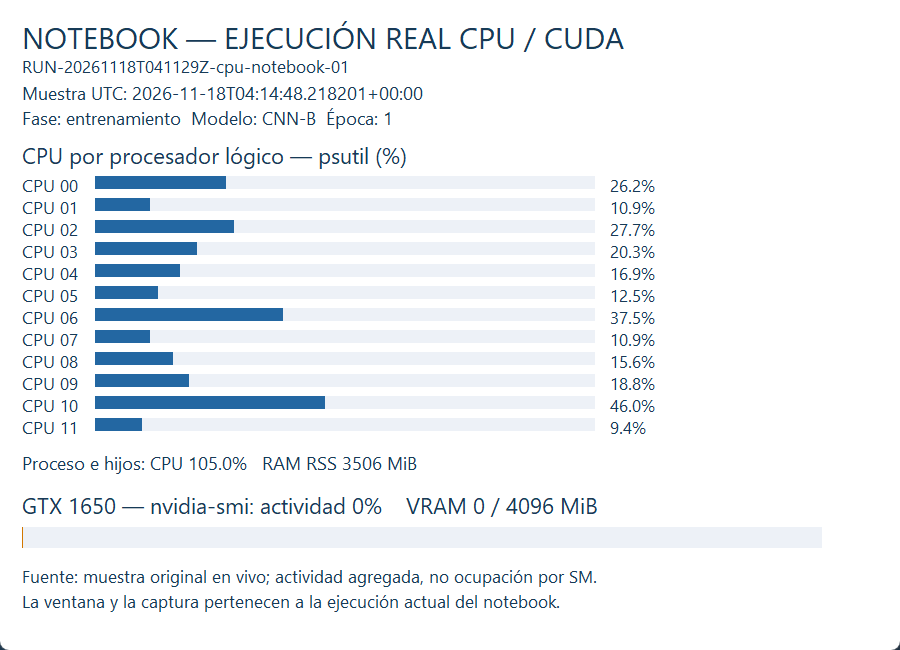

captura-cpu.png {
  "tipo": "captura_original_monitor_en_vivo",
  "captura_utc": "2026-11-18T04:14:49.708647+00:00",
  "run_id": "RUN-20261118T041129Z-cpu-notebook-01",
  "muestra_original": {
    "utc": "2026-11-18T04:14:48.218201+00:00",
    "transcurrido_s": "190.72824279998895",
    "fase": "entrenamiento",
    "modelo": "CNN-B",
    "epoca": "1",
    "cpu_procesos_pct": "105.02079461684895",
    "rss_bytes": "3676446720",
    "gpu_util_pct": "0.0",
    "gpu_mem_util_pct": "0.0",
    "gpu_mem_used_mib": "0.0",
    "gpu_temperatura_c": "54.0",
    "cpu_logico_00_pct": "26.2",
    "cpu_logico_01_pct": "10.9",
    "cpu_logico_02_pct": "27.7",
    "cpu_logico_03_pct": "20.3",
    "cpu_logico_04_pct": "16.9",
    "cpu_logico_05_pct": "12.5",
    "cpu_logico_06_pct": "37.5",
    "cpu_logico_07_pct": "10.9",
    "cpu_logico_08_pct": "15.6",
    "cpu_logico_09_pct": "18.8",
    "cpu_logico_10_pct": "46.0",
    "cpu_logico_11_pct": "9.4"
  },
  "sha256": "85d367cbe2b6d2ef83b5ab0ad99062812d9

In [ ]:
monitor_stop.set(); monitor_thread.join(timeout=15)
threadpool_guard.__exit__(None,None,None)
recursos_actuales = pd.read_csv(directory / "recursos.csv")
display(recursos_actuales)
columnas_cpu=[c for c in recursos_actuales if c.startswith("cpu_logico_")]
fig, axes = plt.subplots(2,1,figsize=(12,6))
for col in columnas_cpu: axes[0].plot(recursos_actuales.transcurrido_s,recursos_actuales[col],label=col)
axes[0].set(ylabel="CPU por lógico (%)",title="Uso real registrado durante esta ejecución")
axes[0].legend(ncol=4,fontsize=7)
axes[1].plot(recursos_actuales.transcurrido_s,recursos_actuales.gpu_util_pct,label="Actividad GPU (%)")
axes[1].plot(recursos_actuales.transcurrido_s,recursos_actuales.gpu_mem_used_mib/4096*100,label="VRAM ocupada (%)")
axes[1].set(xlabel="Tiempo de proceso (s)",ylabel="Porcentaje");axes[1].legend();fig.tight_layout();mostrar_figura(fig)
for captura in sorted(directory.glob("captura-*.png")):
    display(NotebookImage(filename=str(captura)))
    print(captura.name, (captura.with_suffix(".json")).read_text(encoding="utf8"))
write_json(directory / "salida.json",dict(codigo=0,fin_utc=utc(),tipo="ejecucion_directa_notebook"))
print("EJECUCIÓN NUEVA COMPLETA:", directory.name)


## Cinco mediciones históricas del informe — registros íntegros

Esta sección es histórica y está separada de la corrida nueva anterior. Se muestran stdout/stderr completos,épocas,métricas y tiempos de cada RUN. No se vuelven a entrenar ni se mezclan con el promedio original.

### Registro histórico RUN-20261117T171942Z-cpu-01

In [ ]:
historico = ROOT / "resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T171942Z-cpu-01
[2026-11-17T17:20:03.105949+00:00] inicializacion_y_warmup {'modelo': 'CNN-A'}
[2026-11-17T17:20:05.039629+00:00] inicializacion_y_warmup {'modelo': 'CNN-B'}
[2026-11-17T17:20:09.774035+00:00] inicializacion_y_warmup {'modelo': 'FC-A'}
[2026-11-17T17:20:11.653534+00:00] inicializacion_y_warmup {'modelo': 'FC-B'}
[2026-11-17T17:20:14.133554+00:00] inicializacion_y_warmup {'modelo': 'CNN-A+aug'}
[2026-11-17T17:20:16.570466+00:00] inicializacion_y_warmup {'modelo': 'CNN-B+aug'}
[2026-11-17T17:20:22.026571+00:00] preparacion_cpu {}
RESULTADO preparacion_cpu: 17.963012 s
[2026-11-17T17:20:39.998875+00:00] entrenamiento_CNN-A {}
[2026-11-17T17:20:40.202822+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 1}
EPOCH CNN-A 1/15 {'accuracy': 0.17233169078826904, 'loss': 2.941843032836914, 'val_accuracy': 0.40306514501571655, 'val_loss': 2.09909987449646}
[2026-11-17T17:20:50.008896+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 2}
EPOCH CNN-A 2/15 {'accu

I0000 00:00:1794935984.686130   60916 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794935988.716616   60916 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794936002.686670   60916 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1794936003.343010   60916 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is

,modelo,epoca,duracion_s,validacion_s,accuracy,loss,val_accuracy,val_loss
0,CNN-A,1,9.804566,0.806539,0.172332,2.941843,0.403065,2.099100
1,CNN-A,2,8.640221,0.592013,0.424138,1.881155,0.606130,1.357209
2,CNN-A,3,8.207748,0.522941,0.575123,1.341297,0.688506,1.035756
3,CNN-A,4,8.140782,0.516921,0.668145,1.044865,0.791571,0.745192
4,CNN-A,5,8.056329,0.493542,0.740722,0.800756,0.814943,0.637783
5,CNN-A,6,8.330881,0.513830,0.795320,0.642778,0.843295,0.529143
6,CNN-A,7,8.659966,0.538904,0.820525,0.548367,0.864751,0.444818
7,CNN-A,8,8.884766,0.596345,0.846305,0.463251,0.886207,0.385231
8,CNN-A,9,8.726713,0.515041,0.867898,0.411775,0.907280,0.312747
9,CNN-A,10,8.126315,0.502875,0.884154,0.353000,0.921456,0.268770


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,preparacion_cpu,pared,17.963012,2026-11-17T17:20:22.026628+00:00,2026-11-17T17:20:39.989647+00:00,NaN,NaN,17400,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,NaN
1,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,entrenamiento_CNN-A,pared,129.077673,2026-11-17T17:20:39.998916+00:00,2026-11-17T17:22:49.076601+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
2,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,validacion_anidada_CNN-A,pared,8.299906,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
3,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,evaluacion_CNN-A,pared,0.904451,2026-11-17T17:22:49.082746+00:00,2026-11-17T17:22:49.987208+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,NaN
4,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,entrenamiento_CNN-B,pared,803.847403,2026-11-17T17:22:49.994242+00:00,2026-11-17T17:36:13.841655+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
5,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,validacion_anidada_CNN-B,pared,31.305076,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
6,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,evaluacion_CNN-B,pared,2.444951,2026-11-17T17:36:13.845992+00:00,2026-11-17T17:36:16.290953+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,NaN
7,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,diagnostico_cnn,pared,2.546739,2026-11-17T17:36:16.294259+00:00,2026-11-17T17:36:18.841012+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,NaN
8,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,entrenamiento_FC-A,pared,48.520110,2026-11-17T17:36:18.887092+00:00,2026-11-17T17:37:07.407217+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T171942Z-cpu-01/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
9,EXP-002,RUN-20261117T171942Z-cpu-01,cpu,1,validacion_anidada_FC-A,pared,2.303337,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6

{
  "modelos": {
    "CNN-A": {
      "accuracy": 0.9306513667106628,
      "loss": 0.21349219977855682
    },
    "CNN-B": {
      "accuracy": 0.961685836315155,
      "loss": 0.12146297842264175
    },
    "FC-A": {
      "accuracy": 0.530651330947876,
      "loss": 1.5230441093444824
    },
    "FC-B": {
      "accuracy": 0.44291186332702637,
      "loss": 1.7380640506744385
    },
    "RF-B": {
      "accuracy": 0.8977011494252873,
      "val_accuracy": 0.9088122605363985
    },
    "CNN-B+aug": {
      "accuracy": 0.9532567262649536,
      "loss": 0.12814120948314667
    }
  },
  "mejor_cnn": "CNN-B",
  "mejor_rf": "RF-B",
  "modelo_final": "CNN-B",
  "pca_varianza": 0.9621036052703857,
  "grupo_accuracy": {
    "CNN-A": 0.13333333333333333,
    "CNN-B": 0.06666666666666667,
    "FC-A": 0.06666666666666667,
    "FC-B": 0.06666666666666667,
    "CNN-B+aug": 0.26666666666666666,
    "RF-B": 0.0
  }
}



### Registro histórico RUN-20261117T175407Z-cpu-02

In [ ]:
historico = ROOT / "resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T175407Z-cpu-02
[2026-11-17T17:54:49.447127+00:00] inicializacion_y_warmup {'modelo': 'CNN-A'}
[2026-11-17T17:54:51.458562+00:00] inicializacion_y_warmup {'modelo': 'CNN-B'}
[2026-11-17T17:54:56.419122+00:00] inicializacion_y_warmup {'modelo': 'FC-A'}
[2026-11-17T17:54:58.255326+00:00] inicializacion_y_warmup {'modelo': 'FC-B'}
[2026-11-17T17:55:00.621787+00:00] inicializacion_y_warmup {'modelo': 'CNN-A+aug'}
[2026-11-17T17:55:03.107482+00:00] inicializacion_y_warmup {'modelo': 'CNN-B+aug'}
[2026-11-17T17:55:08.369076+00:00] preparacion_cpu {}
RESULTADO preparacion_cpu: 17.439833 s
[2026-11-17T17:55:25.817966+00:00] entrenamiento_CNN-A {}
[2026-11-17T17:55:25.941974+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 1}
EPOCH CNN-A 1/15 {'accuracy': 0.17233169078826904, 'loss': 2.941843032836914, 'val_accuracy': 0.40306514501571655, 'val_loss': 2.09909987449646}
[2026-11-17T17:55:34.771970+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 2}
EPOCH CNN-A 2/15 {'accu

,modelo,epoca,duracion_s,validacion_s,accuracy,loss,val_accuracy,val_loss
0,CNN-A,1,8.828497,0.676006,0.172332,2.941843,0.403065,2.099100
1,CNN-A,2,8.189876,0.495607,0.424138,1.881155,0.606130,1.357209
2,CNN-A,3,8.168086,0.505717,0.575123,1.341297,0.688506,1.035756
3,CNN-A,4,8.080638,0.495674,0.668145,1.044865,0.791571,0.745192
4,CNN-A,5,8.123510,0.519124,0.740722,0.800756,0.814943,0.637783
5,CNN-A,6,8.127172,0.510548,0.795320,0.642778,0.843295,0.529143
6,CNN-A,7,8.147609,0.529907,0.820525,0.548367,0.864751,0.444818
7,CNN-A,8,8.514979,0.536956,0.846305,0.463251,0.886207,0.385231
8,CNN-A,9,8.070143,0.511766,0.867898,0.411775,0.907280,0.312747
9,CNN-A,10,8.192113,0.525235,0.884154,0.353000,0.921456,0.268770


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,preparacion_cpu,pared,17.439833,2026-11-17T17:55:08.369120+00:00,2026-11-17T17:55:25.808961+00:00,NaN,NaN,17400,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,NaN
1,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,entrenamiento_CNN-A,pared,123.117082,2026-11-17T17:55:25.818012+00:00,2026-11-17T17:57:28.935113+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
2,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,validacion_anidada_CNN-A,pared,7.878980,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
3,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,evaluacion_CNN-A,pared,0.774289,2026-11-17T17:57:28.941042+00:00,2026-11-17T17:57:29.715348+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,NaN
4,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,entrenamiento_CNN-B,pared,806.869706,2026-11-17T17:57:29.721474+00:00,2026-11-17T18:10:56.591189+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
5,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,validacion_anidada_CNN-B,pared,32.114380,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
6,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,evaluacion_CNN-B,pared,2.280797,2026-11-17T18:10:56.594941+00:00,2026-11-17T18:10:58.875755+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,NaN
7,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,diagnostico_cnn,pared,2.509121,2026-11-17T18:10:58.880071+00:00,2026-11-17T18:11:01.389203+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,NaN
8,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,entrenamiento_FC-A,pared,51.495011,2026-11-17T18:11:01.413696+00:00,2026-11-17T18:11:52.908723+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T175407Z-cpu-02/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
9,EXP-002,RUN-20261117T175407Z-cpu-02,cpu,2,validacion_anidada_FC-A,pared,2.240287,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6

{
  "modelos": {
    "CNN-A": {
      "accuracy": 0.9306513667106628,
      "loss": 0.21349219977855682
    },
    "CNN-B": {
      "accuracy": 0.9888888597488403,
      "loss": 0.038697749376297
    },
    "FC-A": {
      "accuracy": 0.530651330947876,
      "loss": 1.5230441093444824
    },
    "FC-B": {
      "accuracy": 0.44291186332702637,
      "loss": 1.7380640506744385
    },
    "RF-B": {
      "accuracy": 0.8977011494252873,
      "val_accuracy": 0.9088122605363985
    },
    "CNN-B+aug": {
      "accuracy": 0.8674329519271851,
      "loss": 0.5057448148727417
    }
  },
  "mejor_cnn": "CNN-B",
  "mejor_rf": "RF-B",
  "modelo_final": "CNN-B",
  "pca_varianza": 0.9621036052703857,
  "grupo_accuracy": {
    "CNN-A": 0.13333333333333333,
    "CNN-B": 0.06666666666666667,
    "FC-A": 0.06666666666666667,
    "FC-B": 0.06666666666666667,
    "CNN-B+aug": 0.2,
    "RF-B": 0.0
  }
}



### Registro histórico RUN-20261117T182835Z-cpu-03

In [ ]:
historico = ROOT / "resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T182835Z-cpu-03
[2026-11-17T18:29:05.893534+00:00] inicializacion_y_warmup {'modelo': 'CNN-A'}
[2026-11-17T18:29:07.750721+00:00] inicializacion_y_warmup {'modelo': 'CNN-B'}
[2026-11-17T18:29:12.356283+00:00] inicializacion_y_warmup {'modelo': 'FC-A'}
[2026-11-17T18:29:14.080388+00:00] inicializacion_y_warmup {'modelo': 'FC-B'}
[2026-11-17T18:29:16.298161+00:00] inicializacion_y_warmup {'modelo': 'CNN-A+aug'}
[2026-11-17T18:29:18.702038+00:00] inicializacion_y_warmup {'modelo': 'CNN-B+aug'}
[2026-11-17T18:29:23.914559+00:00] preparacion_cpu {}
RESULTADO preparacion_cpu: 17.072772 s
[2026-11-17T18:29:40.997304+00:00] entrenamiento_CNN-A {}
[2026-11-17T18:29:41.141126+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 1}
EPOCH CNN-A 1/15 {'accuracy': 0.17233169078826904, 'loss': 2.941843032836914, 'val_accuracy': 0.40306514501571655, 'val_loss': 2.09909987449646}
[2026-11-17T18:29:50.987461+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 2}
EPOCH CNN-A 2/15 {'accu

,modelo,epoca,duracion_s,validacion_s,accuracy,loss,val_accuracy,val_loss
0,CNN-A,1,9.845393,0.700431,0.172332,2.941843,0.403065,2.099100
1,CNN-A,2,8.470238,0.533166,0.424138,1.881155,0.606130,1.357209
2,CNN-A,3,8.162859,0.530057,0.575123,1.341297,0.688506,1.035756
3,CNN-A,4,8.239834,0.510455,0.668145,1.044865,0.791571,0.745192
4,CNN-A,5,8.095505,0.509057,0.740722,0.800756,0.814943,0.637783
5,CNN-A,6,8.145071,0.509600,0.795320,0.642778,0.843295,0.529143
6,CNN-A,7,8.065172,0.524803,0.820525,0.548367,0.864751,0.444818
7,CNN-A,8,8.151446,0.498633,0.846305,0.463251,0.886207,0.385231
8,CNN-A,9,8.207677,0.520592,0.867898,0.411775,0.907280,0.312747
9,CNN-A,10,8.195694,0.516948,0.884154,0.353000,0.921456,0.268770


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,preparacion_cpu,pared,17.072772,2026-11-17T18:29:23.914608+00:00,2026-11-17T18:29:40.987387+00:00,NaN,NaN,17400,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,NaN
1,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,entrenamiento_CNN-A,pared,125.116867,2026-11-17T18:29:40.997346+00:00,2026-11-17T18:31:46.114224+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
2,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,validacion_anidada_CNN-A,pared,7.945288,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
3,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,evaluacion_CNN-A,pared,0.785862,2026-11-17T18:31:46.118026+00:00,2026-11-17T18:31:46.903905+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,NaN
4,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,entrenamiento_CNN-B,pared,802.320202,2026-11-17T18:31:46.910000+00:00,2026-11-17T18:45:09.230217+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
5,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,validacion_anidada_CNN-B,pared,31.500546,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
6,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,evaluacion_CNN-B,pared,2.297889,2026-11-17T18:45:09.233773+00:00,2026-11-17T18:45:11.531676+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,NaN
7,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,diagnostico_cnn,pared,2.476279,2026-11-17T18:45:11.535511+00:00,2026-11-17T18:45:14.011805+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,NaN
8,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,entrenamiento_FC-A,pared,51.378253,2026-11-17T18:45:14.035626+00:00,2026-11-17T18:46:05.413892+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T182835Z-cpu-03/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
9,EXP-002,RUN-20261117T182835Z-cpu-03,cpu,3,validacion_anidada_FC-A,pared,2.290387,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6

{
  "modelos": {
    "CNN-A": {
      "accuracy": 0.9306513667106628,
      "loss": 0.21349219977855682
    },
    "CNN-B": {
      "accuracy": 0.9762452244758606,
      "loss": 0.06832197308540344
    },
    "FC-A": {
      "accuracy": 0.530651330947876,
      "loss": 1.5230441093444824
    },
    "FC-B": {
      "accuracy": 0.44291186332702637,
      "loss": 1.7380640506744385
    },
    "RF-B": {
      "accuracy": 0.8977011494252873,
      "val_accuracy": 0.9088122605363985
    },
    "CNN-B+aug": {
      "accuracy": 0.9367815852165222,
      "loss": 0.17150506377220154
    }
  },
  "mejor_cnn": "CNN-B",
  "mejor_rf": "RF-B",
  "modelo_final": "CNN-B",
  "pca_varianza": 0.9621036052703857,
  "grupo_accuracy": {
    "CNN-A": 0.13333333333333333,
    "CNN-B": 0.2,
    "FC-A": 0.06666666666666667,
    "FC-B": 0.06666666666666667,
    "CNN-B+aug": 0.2,
    "RF-B": 0.0
  }
}



### Registro histórico RUN-20261117T190250Z-cpu-04

In [ ]:
historico = ROOT / "resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T190250Z-cpu-04
[2026-11-17T19:03:10.387055+00:00] inicializacion_y_warmup {'modelo': 'CNN-A'}
[2026-11-17T19:03:12.213685+00:00] inicializacion_y_warmup {'modelo': 'CNN-B'}
[2026-11-17T19:03:16.798852+00:00] inicializacion_y_warmup {'modelo': 'FC-A'}
[2026-11-17T19:03:18.491788+00:00] inicializacion_y_warmup {'modelo': 'FC-B'}
[2026-11-17T19:03:20.725574+00:00] inicializacion_y_warmup {'modelo': 'CNN-A+aug'}
[2026-11-17T19:03:23.040145+00:00] inicializacion_y_warmup {'modelo': 'CNN-B+aug'}
[2026-11-17T19:03:28.303639+00:00] preparacion_cpu {}
RESULTADO preparacion_cpu: 17.267030 s
[2026-11-17T19:03:45.580007+00:00] entrenamiento_CNN-A {}
[2026-11-17T19:03:45.705107+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 1}
EPOCH CNN-A 1/15 {'accuracy': 0.17233169078826904, 'loss': 2.941843032836914, 'val_accuracy': 0.40306514501571655, 'val_loss': 2.09909987449646}
[2026-11-17T19:03:54.680855+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 2}
EPOCH CNN-A 2/15 {'accu

,modelo,epoca,duracion_s,validacion_s,accuracy,loss,val_accuracy,val_loss
0,CNN-A,1,8.974263,0.679363,0.172332,2.941843,0.403065,2.099100
1,CNN-A,2,8.718334,0.496715,0.424138,1.881155,0.606130,1.357209
2,CNN-A,3,8.255065,0.517910,0.575123,1.341297,0.688506,1.035756
3,CNN-A,4,8.192643,0.508542,0.668145,1.044865,0.791571,0.745192
4,CNN-A,5,8.140450,0.506625,0.740722,0.800756,0.814943,0.637783
5,CNN-A,6,8.112928,0.489820,0.795320,0.642778,0.843295,0.529143
6,CNN-A,7,8.113687,0.498485,0.820525,0.548367,0.864751,0.444818
7,CNN-A,8,8.138536,0.496091,0.846305,0.463251,0.886207,0.385231
8,CNN-A,9,8.111021,0.507330,0.867898,0.411775,0.907280,0.312747
9,CNN-A,10,8.151415,0.504517,0.884154,0.353000,0.921456,0.268770


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,preparacion_cpu,pared,17.267030,2026-11-17T19:03:28.303687+00:00,2026-11-17T19:03:45.570725+00:00,NaN,NaN,17400,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,NaN
1,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,entrenamiento_CNN-A,pared,123.739714,2026-11-17T19:03:45.580046+00:00,2026-11-17T19:05:49.319783+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
2,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,validacion_anidada_CNN-A,pared,7.749135,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
3,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,evaluacion_CNN-A,pared,0.759444,2026-11-17T19:05:49.323473+00:00,2026-11-17T19:05:50.082929+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,NaN
4,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,entrenamiento_CNN-B,pared,809.363247,2026-11-17T19:05:50.088935+00:00,2026-11-17T19:19:19.452192+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
5,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,validacion_anidada_CNN-B,pared,31.299847,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
6,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,evaluacion_CNN-B,pared,2.323036,2026-11-17T19:19:19.456028+00:00,2026-11-17T19:19:21.779083+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,NaN
7,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,diagnostico_cnn,pared,0.819401,2026-11-17T19:19:21.782563+00:00,2026-11-17T19:19:22.601977+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,NaN
8,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,entrenamiento_FC-A,pared,50.741554,2026-11-17T19:19:22.625862+00:00,2026-11-17T19:20:13.367431+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T190250Z-cpu-04/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
9,EXP-002,RUN-20261117T190250Z-cpu-04,cpu,4,validacion_anidada_FC-A,pared,2.288549,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6

{
  "modelos": {
    "CNN-A": {
      "accuracy": 0.9306513667106628,
      "loss": 0.21349219977855682
    },
    "CNN-B": {
      "accuracy": 0.928735613822937,
      "loss": 0.25926002860069275
    },
    "FC-A": {
      "accuracy": 0.530651330947876,
      "loss": 1.5230441093444824
    },
    "FC-B": {
      "accuracy": 0.44291186332702637,
      "loss": 1.7380640506744385
    },
    "RF-B": {
      "accuracy": 0.8977011494252873,
      "val_accuracy": 0.9088122605363985
    },
    "CNN-A+aug": {
      "accuracy": 0.8417624235153198,
      "loss": 0.5011962056159973
    }
  },
  "mejor_cnn": "CNN-A",
  "mejor_rf": "RF-B",
  "modelo_final": "CNN-A",
  "pca_varianza": 0.9621036052703857,
  "grupo_accuracy": {
    "CNN-A": 0.13333333333333333,
    "CNN-B": 0.06666666666666667,
    "FC-A": 0.06666666666666667,
    "FC-B": 0.06666666666666667,
    "CNN-A+aug": 0.2,
    "RF-B": 0.0
  }
}



### Registro histórico RUN-20261117T192509Z-cpu-05

In [ ]:
historico = ROOT / "resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05"
print("HISTÓRICO:",historico.name)
print((historico/"stdout.log").read_text(encoding="utf8"))
print("STDERR ORIGINAL:")
print((historico/"stderr.log").read_text(encoding="utf8"))
display(pd.read_csv(historico/"epocas.csv"))
display(pd.read_csv(historico/"tiempos.csv"))
print((historico/"metricas.json").read_text(encoding="utf8"))


HISTÓRICO: RUN-20261117T192509Z-cpu-05
[2026-11-17T19:25:30.781167+00:00] inicializacion_y_warmup {'modelo': 'CNN-A'}
[2026-11-17T19:25:32.620953+00:00] inicializacion_y_warmup {'modelo': 'CNN-B'}
[2026-11-17T19:25:37.217307+00:00] inicializacion_y_warmup {'modelo': 'FC-A'}
[2026-11-17T19:25:38.929986+00:00] inicializacion_y_warmup {'modelo': 'FC-B'}
[2026-11-17T19:25:41.120304+00:00] inicializacion_y_warmup {'modelo': 'CNN-A+aug'}
[2026-11-17T19:25:43.439388+00:00] inicializacion_y_warmup {'modelo': 'CNN-B+aug'}
[2026-11-17T19:25:48.712484+00:00] preparacion_cpu {}
RESULTADO preparacion_cpu: 16.879898 s
[2026-11-17T19:26:05.601802+00:00] entrenamiento_CNN-A {}
[2026-11-17T19:26:05.724072+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 1}
EPOCH CNN-A 1/15 {'accuracy': 0.17233169078826904, 'loss': 2.941843032836914, 'val_accuracy': 0.40306514501571655, 'val_loss': 2.09909987449646}
[2026-11-17T19:26:14.670523+00:00] entrenamiento {'modelo': 'CNN-A', 'epoca': 2}
EPOCH CNN-A 2/15 {'accu

,modelo,epoca,duracion_s,validacion_s,accuracy,loss,val_accuracy,val_loss
0,CNN-A,1,8.944780,0.682130,0.172332,2.941843,0.403065,2.099100
1,CNN-A,2,8.205720,0.535179,0.424138,1.881155,0.606130,1.357209
2,CNN-A,3,8.158649,0.535086,0.575123,1.341297,0.688506,1.035756
3,CNN-A,4,8.077738,0.527218,0.668145,1.044865,0.791571,0.745192
4,CNN-A,5,8.280988,0.518792,0.740722,0.800756,0.814943,0.637783
5,CNN-A,6,8.176102,0.518715,0.795320,0.642778,0.843295,0.529143
6,CNN-A,7,8.088169,0.515094,0.820525,0.548367,0.864751,0.444818
7,CNN-A,8,8.041492,0.514887,0.846305,0.463251,0.886207,0.385231
8,CNN-A,9,8.164093,0.510478,0.867898,0.411775,0.907280,0.312747
9,CNN-A,10,8.150904,0.498647,0.884154,0.353000,0.921456,0.268770


,experimento_id,run_id,dispositivo,repeticion,fase,tipo_medicion,duracion_s,inicio_utc,fin_utc,epocas,pasos,muestras,batch_size,incluido_resumen,estado,configuracion_sha256,datos_sha256,evidencia,motivo
0,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,preparacion_cpu,pared,16.879898,2026-11-17T19:25:48.712532+00:00,2026-11-17T19:26:05.592437+00:00,NaN,NaN,17400,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,NaN
1,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,entrenamiento_CNN-A,pared,123.144968,2026-11-17T19:26:05.601839+00:00,2026-11-17T19:28:08.746827+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
2,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,validacion_anidada_CNN-A,pared,7.928145,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
3,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,evaluacion_CNN-A,pared,0.785053,2026-11-17T19:28:08.752980+00:00,2026-11-17T19:28:09.538048+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,NaN
4,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,entrenamiento_CNN-B,pared,805.848071,2026-11-17T19:28:09.543984+00:00,2026-11-17T19:41:35.392066+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
5,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,validacion_anidada_CNN-B,pared,32.353673,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,Subintervalo de fit: no sumar al total ni tratar como fase adicional.
6,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,evaluacion_CNN-B,pared,2.265277,2026-11-17T19:41:35.396165+00:00,2026-11-17T19:41:37.661457+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,NaN
7,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,diagnostico_cnn,pared,2.499861,2026-11-17T19:41:37.665204+00:00,2026-11-17T19:41:40.165080+00:00,NaN,NaN,2610,NaN,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,NaN
8,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,entrenamiento_FC-A,pared,51.443373,2026-11-17T19:41:40.188755+00:00,2026-11-17T19:42:31.632143+00:00,15.0,1440.0,182700,128.0,True,completada,6e6ffcb7deacc075bbb30224bd6503621cbe83b36297140fda4ff83ad9a60070,6a67443d4804072b4bba1176d33ccee6efc73b09ae0c60a5f10a7a2d9c1b37d2,resultados/secuencial/EXP-002/RUN-20261117T192509Z-cpu-05/tiempos.csv,Incluye validacion; callbacks y duraciones anidadas conservados.
9,EXP-002,RUN-20261117T192509Z-cpu-05,cpu,5,validacion_anidada_FC-A,pared,2.332449,NaN,NaN,15.0,NaN,39150,NaN,True,completada,6e6

{
  "modelos": {
    "CNN-A": {
      "accuracy": 0.9306513667106628,
      "loss": 0.21349219977855682
    },
    "CNN-B": {
      "accuracy": 0.9888888597488403,
      "loss": 0.04795609787106514
    },
    "FC-A": {
      "accuracy": 0.530651330947876,
      "loss": 1.5230441093444824
    },
    "FC-B": {
      "accuracy": 0.44291186332702637,
      "loss": 1.7380640506744385
    },
    "RF-B": {
      "accuracy": 0.8977011494252873,
      "val_accuracy": 0.9088122605363985
    },
    "CNN-B+aug": {
      "accuracy": 0.9704980850219727,
      "loss": 0.09351716935634613
    }
  },
  "mejor_cnn": "CNN-B",
  "mejor_rf": "RF-B",
  "modelo_final": "CNN-B",
  "pca_varianza": 0.9621036052703857,
  "grupo_accuracy": {
    "CNN-A": 0.13333333333333333,
    "CNN-B": 0.26666666666666666,
    "FC-A": 0.06666666666666667,
    "FC-B": 0.06666666666666667,
    "CNN-B+aug": 0.2,
    "RF-B": 0.0
  }
}



## Comparación histórica del informe (no incluye la corrida nueva)

In [ ]:
display(pd.read_csv(ROOT/"resultados/paralelo/EXP-003/comparacion_cnn_b.csv"))
display(pd.read_csv(ROOT/"resultados/paralelo/EXP-003/speedup.csv"))
print("Solo CNN-B base comparable. Preparación1→6workers es mejoraCPU;referencia histórica,RNG distinto y sin afirmación de saturaciónSM/VRAM.")


,dispositivo,run_id,preparacion_cpu_s,entrenamiento_s,evaluacion_cpu_s,validacion_anidada_s,suma_comparable_s,total_continuo_gpu_s,h2d_eventos_s,d2h_eventos_s,computo_intervalos_stream_s,administracion_y_staging_s
0,cpu,RUN-20261117T171942Z-cpu-01,17.963012,803.847403,2.444951,31.305076,824.255365,NaN,NaN,NaN,NaN,NaN
1,cpu,RUN-20261117T175407Z-cpu-02,17.439833,806.869706,2.280797,32.114380,826.590335,NaN,NaN,NaN,NaN,NaN
2,cpu,RUN-20261117T182835Z-cpu-03,17.072772,802.320202,2.297889,31.500546,821.690863,NaN,NaN,NaN,NaN,NaN
3,cpu,RUN-20261117T190250Z-cpu-04,17.267030,809.363247,2.323036,31.299847,828.953313,NaN,NaN,NaN,NaN,NaN
4,cpu,RUN-20261117T192509Z-cpu-05,16.879898,805.848071,2.265277,32.353673,824.993247,NaN,NaN,NaN,NaN,NaN
5,gpu,RUN-20261117T231628Z-gpu-01,7.785163,415.499294,2.168861,31.113583,425.453318,425.904461,3.307184,0.220608,338.869649,41.988270
6,gpu,RUN-20261117T232412Z-gpu-02,8.002736,418.797018,3.144971,32.533162,429.944725,430.397394,3.314661,0.219393,340.523275,42.206527
7,gpu,RUN-20261117T233146Z-gpu-03,8.693341,420.508824,2.478408,33.538533,431.680572,432.131440,3.312559,0.214493,341.571258,41.871980
8,gpu,RUN-20261117T233923Z-gpu-04,7.785700,419.771853,2.313765,32.147011,429.871317,430.323723,3.315666,0.209487,342.159841,41.939848
9,gpu,RUN-20261117T234658Z-gpu-05,7.904785,418.461426,2.354958,32.285709,428.721169,429.172212,3.314539,0.210523,340.950377,41.700278


,fase,n_cpu,n_gpu,media_cpu_s,media_gpu_s,speedup,interpretacion
0,preparacion_cpu_s,5,5,17.324509,8.034345,2.156306,"CPU1vs6workers, no CUDA"
1,entrenamiento_s,5,5,805.649726,418.607683,1.924594,Mismo alcance; incluye transferencias y validacion
2,evaluacion_cpu_s,5,5,2.322390,2.492192,0.931866,Ambas evaluaciones CPU
3,suma_comparable_s,5,5,825.296624,429.134220,1.923167,Mismo alcance; incluye transferencias y validacion


Solo CNN-B base comparable. Preparación1→6workers es mejoraCPU;referencia histórica,RNG distinto y sin afirmación de saturaciónSM/VRAM.


## Alcance de esta ejecución adicional

Las celdas de cálculo anteriores fueron ejecutadas directamente con PCUDA y
conservan sus salidas nativas. Esta corrida adicional no reemplaza las cinco
mediciones históricas del informe. **Los totales continuos de este notebook
incluyen presentación de tablas/gráficas entre fases**; los intervalos fit/evaluate
individuales mantienen sus fronteras. No se mezclan alcances para calcular speedup.

La configuración y el RUN se conservan. Para repetir el entrenamiento debe
prepararse otro EXP/RUN; abrir el notebook permite leer todas sus salidas sin
volver a entrenar. Los avisos del kernel nativo se anexan abajo porque TensorFlow
puede escribir directamente a stderr del sistema, fuera del canal de salida de
las celdas. Este anexo documental no simula una ejecución de código.


## Diagnósticos nativos completos del kernel

Texto literal del tramo de stderr del supervisor correspondiente a este kernel. Los avisos se conservan; la corrida completó con código0.

```text
[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1794975097.674918   34272 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1794975101.879466   34272 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794975118.008385   34272 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
E0000 00:00:1794975118.835930   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794975126.069719   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794975132.956488   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794975156.139242   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794975164.427546   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794975286.350561   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794975341.081677   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794976105.574829   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794976110.882915   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794976152.918274   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794976159.467765   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794976239.866363   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794976256.166191   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794976310.538891   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977095.757009   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794977101.029687   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1794977106.157900   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1794977111.496930   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1794977116.933151   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1794977121.969260   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1794977127.066670   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1794977132.659996   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}
E0000 00:00:1794977138.370022   34272 node_def_util.cc:684] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}

```